# Hate Speech Detection End-to-End: Baseline Classifier -> Tuned Cross-Validated System

**Task.** Build, train and evaluate a complete *hate speech detection* system on the
**Davidson et al. (2017) "Hate Speech and Offensive Language"** corpus: 24,783 English tweets,
each labelled by three or more crowd annotators as **hate speech**, **offensive language**, or
**neither**.

**Why this dataset.** It downloads automatically from the authors' public GitHub repository
(no registration form, no Kaggle token), the whole notebook re-runs on a laptop CPU in a few
minutes, and it has the two properties that make hate speech detection hard in practice: the
class that matters is *rare* (about 6% of the tweets), and it sits right next to a much larger
class - ordinary profanity - that looks almost the same on the surface. It also ships the raw
annotator votes, so we can measure how often the humans disagreed. Everything here transfers
unchanged to another corpus (HateXplain, Founta et al., OLID, a seized-device message export)
by swapping the loader in Part 1.

> **Content warning.** The corpus is real Twitter data and contains slurs, profanity and
> dehumanising language. Every cell that prints text routes it through a display mask
> (`SHOW_RAW = False` in Part 0), but the mask is best-effort. Treat the data file the way you
> would treat any other piece of disturbing evidence.

---

### Two things people mean by "detection accuracy"

A hate speech detector is evaluated in two *different* regimes, and mixing them up is the single
most common mistake in student projects and in papers:

| | **Classification (3-way)** | **Screening / triage (1-vs-rest)** |
|---|---|---|
| Question | "Which category is this message?" | "Should an examiner read this message?" |
| Output | hate / offensive / neither | A score, thresholded into flag / don't flag |
| Natural metrics | Accuracy, precision, recall, F1, confusion matrix | **ROC, AUC, precision-recall, FPR/FNR at a threshold, recall at a review budget** |
| Failure mode | Calling profanity "hate" (or hate "just profanity") | Missing hate speech / burying the examiner in false flags |

A third regime matters in deployment and is usually skipped entirely:

* **In-distribution** evaluation assumes test messages look like training messages.
* **Stress** evaluation asks what happens when they do not: an author who *wants* to evade the
  filter writes `h@te` instead of `hate`, and a perfectly benign message that merely *mentions*
  an identity group ("my gay brother graduated today") must not be flagged. Accuracy on a
  random test split measures neither.

This notebook reports **all three**.

---

### Notebook structure

| Part | Content |
|---|---|
| 0 | Configuration, seeds, reproducibility |
| 1 | Download the dataset if it is not already cached; integrity checks; first look |
| 2 | **Basic** preparation: lowercase + a single stratified hold-out split |
| 3 | **Basic** model: bag-of-words + Multinomial Naive Bayes |
| 4 | Shared evaluation toolkit (written once, used by every model) |
| 5 | Evaluate the baseline: accuracy / precision / recall, confusion matrix, ROC/AUC |
| 6 | Screening view of the baseline: score distributions, EER, FPR/FNR, precision-recall, review budget |
| 7 | **Better** preparation: tweet-aware normalisation, near-duplicate grouping, group k-fold, in-fold augmentation (no leakage) |
| 8 | **Better** model: word + character TF-IDF -> class-weighted logistic regression, tuned in a nested grid search |
| 9 | Evaluate the improved model on out-of-fold predictions (same toolkit) |
| 10 | Stress tests: evasion by obfuscation, and false flags on benign identity mentions |
| 11 | Error analysis: what the model keys on, annotator disagreement, confident mistakes |
| 12 | Model comparison, deployment cost (model size + latency), saving the model |
| 13 | Forensic triage report: hashing the evidence, scoring it, writing a defensible report |
| 14 | Limitations, legal / ethical notes, extensions, lab questions |

## Part 0 - Configuration and reproducibility

Every knob that changes the experiment lives in this one cell, so the rest of the notebook
stays declarative. Seeding matters more than usual here: the class we care about has only
about 1,400 examples, so hate-class recall moves by a noticeable margin between random splits,
and an unseeded notebook produces numbers you cannot defend.

In [1]:
# If anything is missing:  pip install numpy scipy scikit-learn matplotlib pandas joblib
import os
import re
import sys
import html
import json
import time
import random
import hashlib
import warnings
import urllib.request
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, auc, average_precision_score,
                             balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_recall_fscore_support,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedGroupKFold,
                                     train_test_split)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import label_binarize
import joblib

# ---------------------------------------------------------------- reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)           # all stochastic steps draw from seeded generators

# ---------------------------------------------------------------- paths
DATA_HOME  = Path("./data")                 # dataset cache (download target)
FIG_DIR    = Path("./figures")              # every figure is also written to disk
MODEL_DIR  = Path("./models")               # trained model + metadata
REPORT_DIR = Path("./reports")              # Part 13 forensic report + evidence file
for d in (DATA_HOME, FIG_DIR, MODEL_DIR, REPORT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- dataset source
# Davidson, Warmsley, Macy & Weber (ICWSM 2017). First URL is the authors' repository,
# the second is a CDN mirror of the same file.
DATA_URLS = [
    "https://raw.githubusercontent.com/t-davidson/hate-speech-and-offensive-language/"
    "master/data/labeled_data.csv",
    "https://cdn.jsdelivr.net/gh/t-davidson/hate-speech-and-offensive-language@master/"
    "data/labeled_data.csv",
]

# ---------------------------------------------------------------- label scheme
HATE, OFFENSIVE, NEITHER = 0, 1, 2          # the corpus' own integer coding
CLASSES     = np.array([HATE, OFFENSIVE, NEITHER])
CLASS_NAMES = ["hate", "offensive", "neither"]
CLASS_COLOR = {HATE: "tab:red", OFFENSIVE: "tab:orange", NEITHER: "tab:green"}

# ---------------------------------------------------------------- experiment settings
TEST_FRACTION = 0.20       # Part 2 hold-out
N_SPLITS      = 5          # Part 7 stratified *group* k-fold (every tweet scored exactly once)
N_AUG         = 1          # Part 7: 1 obfuscated copy per training message (2x data)
AUG_STRENGTH  = 0.30       # fraction of words perturbed in an augmented copy
FAST_MODE     = False      # True -> one hyperparameter setting and no augmentation
SHOW_RAW      = False      # True -> print tweets unmasked (instructor / private use only)

# Hyperparameter grid searched *inside* each training fold (nested CV -> unbiased estimate)
PARAM_GRID = ({"clf__C": [1.0]} if FAST_MODE else
              {"clf__C": [0.3, 1.0, 3.0]})

# Plot styling
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "font.size": 9, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.constrained_layout.use": True})   # keeps suptitles clear

def savefig(fig, name):
    """Persist a figure next to the notebook so it can go straight into a report."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    return path

print(f"python       {sys.version.split()[0]}")
print(f"numpy        {np.__version__}")
print(f"pandas       {pd.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"seed={SEED} | fast_mode={FAST_MODE} | show_raw={SHOW_RAW} | "
      f"data_home={DATA_HOME.resolve()}")

python       3.13.16
numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1
seed=42 | fast_mode=False | show_raw=False | data_home=/home/claude/work/final3/data


## Part 1 - Download the dataset (only if it is not already there)

The loader looks for `data/labeled_data.csv` first, so the download happens exactly once and
every later run is offline. The file is validated before it is trusted (expected columns,
plausible row count) and written atomically, so an interrupted download cannot leave a
half-file that silently becomes "the dataset".

The loader also carries an **offline fallback**: if the machine has no network access it
synthesises a structurally similar corpus (three classes with the same imbalance, simulated
annotator votes, templated text with mentions / URLs / hashtags) so the full pipeline still
runs and can be demonstrated. That fallback is clearly flagged and is *not* a substitute for
real data - absolute numbers from it mean nothing.

**What is in the file.** One row per tweet: `count` = number of annotators who judged it,
`hate_speech` / `offensive_language` / `neither` = how many of them voted for each category,
`class` = the majority label, `tweet` = the text. The definition the annotators were given is
the one to keep in mind throughout: *hate speech* is language that expresses hatred towards a
targeted group or is intended to be derogatory, humiliating or insulting to its members -
**not** merely the presence of an offensive word.

In [2]:
def _make_synthetic_messages(n=3000, rng=None):
    """
    OFFLINE FALLBACK ONLY. Builds a toy corpus with the same schema and the same statistical
    shape as the real one: ~6% hate / ~77% offensive / ~17% neither, three simulated annotators
    per message who sometimes disagree, and Twitter-style noise (mentions, URLs, hashtags).
    The "hate" class deliberately uses generic group-directed phrasing with no real slurs.
    """
    rng = rng or np.random.default_rng(SEED)
    neutral_open = ["just finished", "looking forward to", "really enjoyed", "thinking about",
                    "so happy about", "cant wait for", "had a great time at", "thanks for",
                    "finally got to see", "reading about", "still smiling about"]
    neutral_obj  = ["the game tonight", "my new job", "the weekend", "this book",
                    "dinner with friends", "the concert", "class today", "the park",
                    "my workout", "the movie", "your help", "the birds outside",
                    "the yankees game", "this sunny weather", "the science museum"]
    off_subj = ["this game", "my phone", "this traffic", "that ref", "the wifi", "this class",
                "that movie", "your team", "this weather", "that song", "my boss"]
    off_pred = ["is trash", "is damn stupid", "sucks so bad", "is crap", "is a joke you idiot",
                "pisses me off", "is garbage dumbass", "can go to hell", "is so damn annoying",
                "is straight up crap lol"]
    hate_subj = ["those people", "that whole group", "all of them", "their kind",
                 "every one of them", "that community", "people like them"]
    hate_pred = ["are vermin", "are subhuman", "should be deported", "dont belong here",
                 "are a disease", "should not have rights", "are all criminals",
                 "are inferior", "need to be removed from our country", "are parasites",
                 "should go back where they came from"]
    fillers = ["", "", "", "lol", "smh", "tbh", "fr", "@user123", "@some_one",
               "http://t.co/abc123", "#mood", "!!!", "RT @friend:"]

    rows = []
    for _ in range(n):
        true = int(rng.choice(CLASSES, p=[0.06, 0.77, 0.17]))
        if true == NEITHER:
            text = f"{rng.choice(neutral_open)} {rng.choice(neutral_obj)}"
        elif true == OFFENSIVE:
            text = f"{rng.choice(off_subj)} {rng.choice(off_pred)}"
        else:
            text = f"{rng.choice(hate_subj)} {rng.choice(hate_pred)}"
            if rng.random() < 0.4:                       # hate often also carries profanity
                text += f" and {rng.choice(off_subj)} {rng.choice(off_pred)}"
        pre, post = rng.choice(fillers), rng.choice(fillers)
        text = " ".join(t for t in (pre, text, post) if t)
        # three annotators; each is right 85% of the time, otherwise picks another class
        votes = np.zeros(3, dtype=int)
        for _a in range(3):
            v = true if rng.random() < 0.85 else int(rng.choice(CLASSES[CLASSES != true]))
            votes[v] += 1
        label = int(votes.argmax()) if votes.max() >= 2 else true
        rows.append((3, votes[HATE], votes[OFFENSIVE], votes[NEITHER], label, text))
    return pd.DataFrame(rows, columns=["count", "hate_speech", "offensive_language",
                                       "neither", "class", "tweet"])


REQUIRED_COLUMNS = ["count", "hate_speech", "offensive_language", "neither", "class", "tweet"]

def load_hate_speech_dataset(data_home=DATA_HOME, allow_synthetic_fallback=True):
    """
    Download-if-missing loader.

    Returns
    -------
    df     : DataFrame with columns text, label, n_annotators, votes_hate, votes_offensive,
             votes_neither (one row per message)
    source : str -- "davidson-2017" or "synthetic-fallback"
    """
    data_home = Path(data_home)
    data_home.mkdir(parents=True, exist_ok=True)
    cache = data_home / "labeled_data.csv"

    def _valid(path):
        try:
            head = pd.read_csv(path, nrows=5)
            return all(c in head.columns for c in REQUIRED_COLUMNS)
        except Exception:
            return False

    try:
        if cache.exists() and _valid(cache):
            print(f"[cache] {cache} already present ({cache.stat().st_size/1e6:.2f} MB) "
                  f"-- skipping download")
        else:
            print(f"[download] {cache} not found -- fetching the Davidson et al. corpus ...")
            last_error = None
            for url in DATA_URLS:
                try:
                    tmp = cache.with_suffix(".part")
                    with urllib.request.urlopen(url, timeout=30) as resp:
                        tmp.write_bytes(resp.read())
                    if not _valid(tmp):
                        raise ValueError("downloaded file does not have the expected columns")
                    tmp.replace(cache)                      # atomic: no half-written cache
                    print(f"[download] ok  <- {url.split('/')[2]}  "
                          f"({cache.stat().st_size/1e6:.2f} MB)")
                    break
                except Exception as exc:                    # try the next mirror
                    last_error = exc
                    print(f"[download] failed <- {url.split('/')[2]}: "
                          f"{type(exc).__name__}: {exc}")
            else:
                raise RuntimeError(f"all download sources failed ({last_error})")
        raw, source = pd.read_csv(cache), "davidson-2017"
    except Exception as exc:                                # no network, proxy, 404 ...
        if not allow_synthetic_fallback:
            raise
        print(f"[warning] real dataset unavailable ({type(exc).__name__}: {exc})")
        print("[warning] falling back to SYNTHETIC data -- pipeline is valid, "
              "the numbers are not real detection performance.")
        print("[warning] the commentary in this notebook describes the REAL corpus and will "
              "not match what the synthetic data shows.")
        raw, source = _make_synthetic_messages(rng=np.random.default_rng(SEED)), \
                      "synthetic-fallback"

    df = pd.DataFrame({
        "text":            raw["tweet"].astype(str),
        "label":           raw["class"].astype(int),
        "n_annotators":    raw["count"].astype(int),
        "votes_hate":      raw["hate_speech"].astype(int),
        "votes_offensive": raw["offensive_language"].astype(int),
        "votes_neither":   raw["neither"].astype(int),
    }).reset_index(drop=True)
    return df, source


df, DATA_SOURCE = load_hate_speech_dataset()
texts_raw = df["text"].to_numpy(dtype=object)   # original strings -- never modified in place
y         = df["label"].to_numpy()              # 0 = hate, 1 = offensive, 2 = neither
N         = len(df)

# SHA-256 of the corpus as loaded: record it, so "which data produced these numbers?" always
# has an answer (same habit as hashing a disk image before analysing it).
DATA_SHA256 = hashlib.sha256("\n".join(texts_raw).encode("utf-8")).hexdigest()
print(f"loaded {N:,} messages from '{DATA_SOURCE}'   sha256(text column) = {DATA_SHA256[:16]}...")

[download] data/labeled_data.csv not found -- fetching the Davidson et al. corpus ...


[download] ok  <- raw.githubusercontent.com  (2.55 MB)
loaded 24,783 messages from 'davidson-2017'   sha256(text column) = e7a44cb4b68c2c42...


In [3]:
# ---- Sanity / integrity check: never trust a dataset you have not looked at -----------
counts   = np.bincount(y, minlength=len(CLASSES))
lengths  = np.array([len(t) for t in texts_raw])
votes    = df[["votes_hate", "votes_offensive", "votes_neither"]].to_numpy()
agreement = votes.max(axis=1) / df["n_annotators"].to_numpy()      # 1.0 = unanimous

print(f"source               : {DATA_SOURCE}")
print(f"messages             : {N:,}")
for c, name in zip(CLASSES, CLASS_NAMES):
    print(f"  class {c} {name:<10}: {counts[c]:>6,}  ({counts[c]/N:6.2%})")
print(f"imbalance ratio      : {counts.max()/counts.min():.1f} : 1  (largest : smallest class)")
print(f"majority-class rate  : {counts.max()/N:.2%}   <- accuracy of a model that always "
      f"answers '{CLASS_NAMES[int(counts.argmax())]}'")
print(f"length (characters)  : min={lengths.min()}  median={int(np.median(lengths))}  "
      f"max={lengths.max()}")
print(f"empty / NaN text     : {(lengths == 0).sum()} / {df['text'].isna().sum()}")
print(f"labels outside 0..2  : {(~np.isin(y, CLASSES)).sum()}")
print(f"annotators per item  : min={df['n_annotators'].min()}  "
      f"median={int(df['n_annotators'].median())}  max={df['n_annotators'].max()}")
print(f"unanimous labels     : {(agreement == 1).mean():.2%} of messages")
for c, name in zip(CLASSES, CLASS_NAMES):
    print(f"  unanimous within {name:<10}: {(agreement[y == c] == 1).mean():.2%}")

# Exact-duplicate check: duplicated rows across a train/test split silently inflate accuracy.
print(f"exact duplicate texts: {N - len(set(texts_raw))}")
assert counts.min() >= 10, "need a workable number of examples in every class"

source               : davidson-2017
messages             : 24,783
  class 0 hate      :  1,430  ( 5.77%)
  class 1 offensive : 19,190  (77.43%)
  class 2 neither   :  4,163  (16.80%)
imbalance ratio      : 13.4 : 1  (largest : smallest class)
majority-class rate  : 77.43%   <- accuracy of a model that always answers 'offensive'
length (characters)  : min=5  median=81  max=754
empty / NaN text     : 0 / 0
labels outside 0..2  : 0
annotators per item  : min=3  median=3  max=9
unanimous labels     : 70.54% of messages
  unanimous within hate      : 18.39%
  unanimous within offensive : 74.76%
  unanimous within neither   : 68.99%
exact duplicate texts: 0


In [4]:
# ---- Two word lists, learned from the data (no slur list is hard-coded in this notebook) ---
# A word is "enriched" in a set of messages if it appears in at least `min_df` messages and
# is much more frequent in that set than in the "neither" class (smoothed log-odds).
def enriched_words(texts, positive, negative, min_df, min_log_odds=2.0):
    cv = CountVectorizer(binary=True, lowercase=True,
                         token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b")
    M = cv.fit_transform(texts)
    vocab = np.array(cv.get_feature_names_out())
    df_pos = np.asarray(M[positive].sum(axis=0)).ravel()
    df_neg = np.asarray(M[negative].sum(axis=0)).ravel()
    log_odds = (np.log((df_pos + 0.5) / (positive.sum() + 1.0))
                - np.log((df_neg + 0.5) / (negative.sum() + 1.0)))
    return set(vocab[(df_pos + df_neg >= min_df) & (log_odds >= min_log_odds)])

# (1) ABUSE_LEXICON: words typical of abusive (hate OR offensive) messages. Used as a crude
#     keyword detector in the separability preview below.
ABUSE_LEXICON = enriched_words(texts_raw, y != NEITHER, y == NEITHER, min_df=10)
# (2) MASK_LEXICON: the same list plus rarer words typical of the hate class. Used ONLY to
#     star out words when text is printed. Deliberately over-inclusive.
MASK_LEXICON  = ABUSE_LEXICON | enriched_words(texts_raw, y == HATE, y == NEITHER, min_df=5)
_ABUSE_STEMS = tuple(sorted(w for w in ABUSE_LEXICON if len(w) >= 4))
_MASK_STEMS  = tuple(sorted(w for w in MASK_LEXICON if len(w) >= 4))

def in_lexicon(word):
    w = word.lower()
    return w in ABUSE_LEXICON or w.startswith(_ABUSE_STEMS)

def _star(word):
    return word[0] + "*" * (len(word) - 2) + word[-1] if len(word) > 2 else word[0] + "*"

def mask_text(text, width=None):
    """Mask listed words (and account names) for display: 'word' -> 'w**d'. Best-effort and
    display-only -- models always see the unmasked text."""
    out = str(text)
    if not SHOW_RAW:
        out = re.sub(r"@\w+", "@user", out)               # do not reprint account names
        out = re.sub(r"[A-Za-z][A-Za-z']+",
                     lambda m: _star(m.group())
                     if (m.group().lower() in MASK_LEXICON
                         or m.group().lower().startswith(_MASK_STEMS)) else m.group(), out)
    out = " ".join(out.split())
    return out if width is None or len(out) <= width else out[:width - 3] + "..."

print(f"abuse lexicon: {len(ABUSE_LEXICON)} words | display-mask lexicon: {len(MASK_LEXICON)} "
      f"words, both learned from the corpus (display masking is {'OFF' if SHOW_RAW else 'ON'})")

# ---- Look at the data: a few messages per class ---------------------------------------
peek_rng = np.random.default_rng(SEED)
for c, name in zip(CLASSES, CLASS_NAMES):
    print(f"\n--- {name.upper()} (class {c}) ---")
    for i in peek_rng.choice(np.flatnonzero(y == c), size=3, replace=False):
        v = votes[i]
        print(f"  [votes h/o/n = {v[0]}/{v[1]}/{v[2]}]  {mask_text(texts_raw[i], 95)}")

abuse lexicon: 103 words | display-mask lexicon: 144 words, both learned from the corpus (display masking is ON)

--- HATE (class 0) ---
  [votes h/o/n = 2/0/1]  Only white trash watch football.
  [votes h/o/n = 2/1/0]  @user @user send them damn b*****s back where they belong n the US a**t it
  [votes h/o/n = 2/1/0]  RT @user: ur a f****t if you change your name to your bday just so you can get bday tweets. ...

--- OFFENSIVE (class 1) ---
  [votes h/o/n = 0/3/0]  ' I still don't got the time for a b***h to be actin iffy &#1043323; .
  [votes h/o/n = 0/3/0]  RT @user: Anytime a girl asks you for help, tell that b***h to ask Channing Tatum since that...
  [votes h/o/n = 0/3/0]  That b***h is hella cranky today. Someone hand her a joint.

--- NEITHER (class 2) ---
  [votes h/o/n = 0/1/2]  My pits be s*****n from doin dem flows. Is hard on a ol colored body in da heat. Dem white w...
  [votes h/o/n = 0/0/3]  just found out @user has an #Australian president! #hoosiers are my team #hoosie

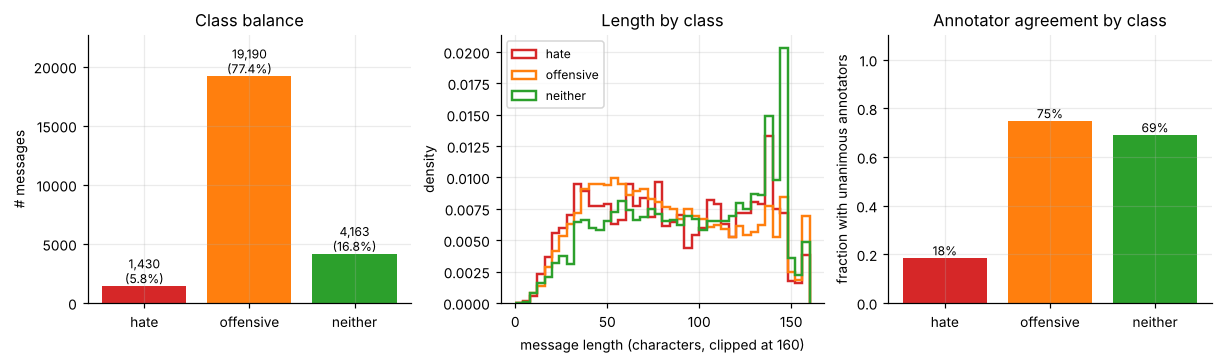

Length carries almost no signal. Agreement does: the annotators themselves were far less sure about 'hate' than about the other two classes -- that is a ceiling on what any model trained on these labels can be asked to do.


In [5]:
# ---- Look at the data: balance, length, and how much the annotators agreed -------------
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))

axes[0].bar(CLASS_NAMES, counts, color=[CLASS_COLOR[c] for c in CLASSES])
for i, v in enumerate(counts):
    axes[0].text(i, v, f"{v:,}\n({v/N:.1%})", ha="center", va="bottom", fontsize=8)
axes[0].set_ylim(0, counts.max() * 1.18); axes[0].set_ylabel("# messages")
axes[0].set_title("Class balance")

bins = np.linspace(0, 160, 41)
for c, name in zip(CLASSES, CLASS_NAMES):
    axes[1].hist(np.clip(lengths[y == c], 0, 160), bins=bins, density=True, histtype="step",
                 lw=1.6, color=CLASS_COLOR[c], label=name)
axes[1].set_xlabel("message length (characters, clipped at 160)"); axes[1].set_ylabel("density")
axes[1].set_title("Length by class"); axes[1].legend(fontsize=8)

unanimous = [(agreement[y == c] == 1).mean() for c in CLASSES]
axes[2].bar(CLASS_NAMES, unanimous, color=[CLASS_COLOR[c] for c in CLASSES])
for i, v in enumerate(unanimous):
    axes[2].text(i, v, f"{v:.0%}", ha="center", va="bottom", fontsize=8)
axes[2].set_ylim(0, 1.1); axes[2].set_ylabel("fraction with unanimous annotators")
axes[2].set_title("Annotator agreement by class")
savefig(fig, "01_dataset_overview"); plt.show()

print("Length carries almost no signal. Agreement does: the annotators themselves were far "
      "less sure about 'hate' than about the other two classes -- that is a ceiling on what "
      "any model trained on these labels can be asked to do.")

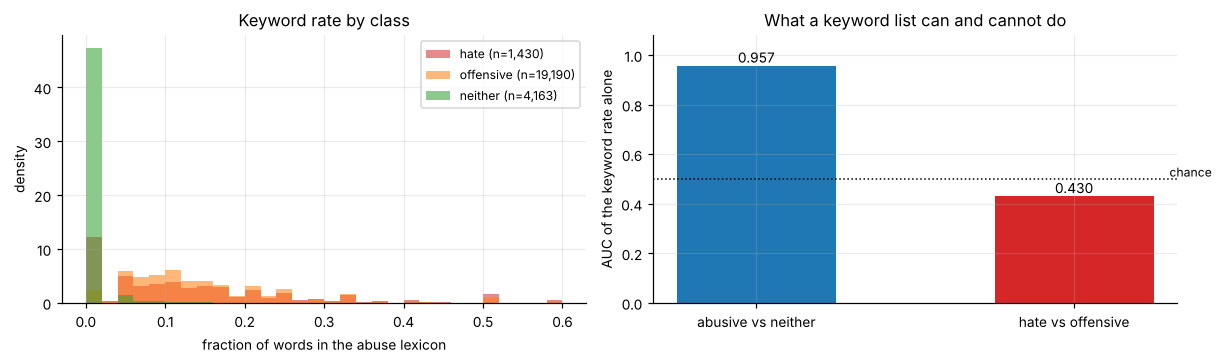

keyword-rate AUC, abusive vs neither : 0.957
keyword-rate AUC, hate vs offensive  : 0.430
A word list finds abusive language well and is close to useless at telling hate speech from ordinary profanity. Finding swear words is easy; the hate / offensive boundary is the actual problem, and it is where every model below loses its points.


In [6]:
# ---- Separability preview -------------------------------------------------------------
# The obvious first idea is a keyword list. Score every message by the fraction of its words
# that are in the abuse lexicon and ask two questions of that single feature:
#   (1) does it separate abusive (hate OR offensive) from neither?
#   (2) does it separate hate from offensive?
# Checking this before modelling tells us how much work the classifier actually has to do.
# (The lexicon was built from these same labels, so both numbers are optimistic -- this is a
#  preview of the problem's shape, not an evaluation.)
def lexicon_rate(text):
    words = re.findall(r"[A-Za-z][A-Za-z']+", text)
    return sum(in_lexicon(w) for w in words) / max(len(words), 1)

lex = np.array([lexicon_rate(t) for t in texts_raw])
auc_abusive = roc_auc_score(y != NEITHER, lex)
auc_hate    = roc_auc_score(y[y != NEITHER] == HATE, lex[y != NEITHER])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
bins = np.linspace(0, 0.6, 31)
for c, name in zip(CLASSES, CLASS_NAMES):
    axes[0].hist(np.clip(lex[y == c], 0, 0.6), bins=bins, density=True, alpha=0.55,
                 color=CLASS_COLOR[c], label=f"{name} (n={counts[c]:,})")
axes[0].set_xlabel("fraction of words in the abuse lexicon"); axes[0].set_ylabel("density")
axes[0].set_title("Keyword rate by class"); axes[0].legend(fontsize=8)

axes[1].bar(["abusive vs neither", "hate vs offensive"], [auc_abusive, auc_hate],
            color=["tab:blue", "tab:red"], width=0.5)
axes[1].axhline(0.5, color="k", ls=":", lw=1); axes[1].text(1.3, 0.51, "chance", fontsize=8)
for i, v in enumerate([auc_abusive, auc_hate]):
    axes[1].text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, 1.08); axes[1].set_ylabel("AUC of the keyword rate alone")
axes[1].set_title("What a keyword list can and cannot do")
savefig(fig, "02_keyword_separability"); plt.show()

print(f"keyword-rate AUC, abusive vs neither : {auc_abusive:.3f}")
print(f"keyword-rate AUC, hate vs offensive  : {auc_hate:.3f}")
print("A word list finds abusive language well and is close to useless at telling hate "
      "speech from ordinary profanity. Finding swear words is easy; the hate / offensive "
      "boundary is the actual problem, and it is where every model below loses its points.")

## Part 2 - Basic dataset preparation

The deliberately simple version: lowercase each message, collapse whitespace, and cut **one**
stratified hold-out split, 80% for training and 20% for testing.

Three things that are easy to get wrong and are handled explicitly here:

1. **Stratify.** The hate class is about 6% of the corpus. An unstratified 20% split can move
   that by a few dozen examples in either direction, and with so few positives that alone
   shifts hate-class recall by a couple of points.
2. **Fit the vectoriser on the training half only.** A vectoriser learns a vocabulary (and,
   for TF-IDF, document frequencies). Fitting it on all messages leaks test-set vocabulary
   into the model. In this notebook the vectoriser always lives inside a `Pipeline`, which
   makes that mistake structurally impossible.
3. **Know the number to beat.** A model that answers "offensive" for every message already
   scores about 77% accuracy on this corpus. Any accuracy figure has to be read against that,
   not against 0% or 33%.

In [7]:
def basic_clean(text):
    """The minimal preparation: lowercase and collapse whitespace."""
    return " ".join(str(text).lower().split())

X_basic = np.array([basic_clean(t) for t in texts_raw], dtype=object)

idx_train, idx_test = train_test_split(
    np.arange(N),
    test_size=TEST_FRACTION,
    stratify=y,                 # keeps the 6 / 77 / 17 class mix identical in both halves
    random_state=SEED,
)
X_train, X_test = X_basic[idx_train], X_basic[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

print(f"train: {len(idx_train):>6,} messages   class mix "
      + " / ".join(f"{(y_train == c).mean():.1%}" for c in CLASSES))
print(f"test : {len(idx_test):>6,} messages   class mix "
      + " / ".join(f"{(y_test == c).mean():.1%}" for c in CLASSES))
print(f"hate-speech messages in the test set: {(y_test == HATE).sum()}  "
      f"<- every hate-class number in Parts 5-6 rests on this many examples")
MAJORITY_ACC = np.bincount(y_test, minlength=3).max() / len(y_test)
print(f"majority-class accuracy on the test set: {MAJORITY_ACC:.4f}")

# No index may appear on both sides -- cheap assertion, catches a whole class of bugs.
assert not (set(idx_train) & set(idx_test)), "train/test index overlap -> data leakage"

train: 19,826 messages   class mix 5.8% / 77.4% / 16.8%
test :  4,957 messages   class mix 5.8% / 77.4% / 16.8%
hate-speech messages in the test set: 286  <- every hate-class number in Parts 5-6 rests on this many examples
majority-class accuracy on the test set: 0.7743


## Part 3 - Basic model: bag-of-words + Multinomial Naive Bayes

The textbook text-classification baseline, kept intentionally plain:

1. **Bag of words.** `CountVectorizer` turns each message into a vector of word counts. Word
   order is discarded; the vocabulary is learned from the training half only.
2. **Multinomial Naive Bayes.** For a message with word counts $x_w$, the score of class $c$ is

   $$\log P(c \mid x) \;\propto\; \log P(c) \;+\; \sum_{w} x_w \,\log P(w \mid c)$$

   a class prior plus one independent vote per word.

The model's output is kept as a full **probability matrix** (messages x classes), not just a
hard label. That is the right output shape for a detection system, and it is what makes the
rest of this notebook possible: `argmax` over classes gives the **3-way classification**, and
the "hate" column on its own is a **screening score** that can be thresholded or used to rank
messages for review. A classifier that only returns a label cannot do the second.

Keep an eye on the $\log P(c)$ term. With 77% of the training data in one class and tweets
that are only a dozen words long, the prior is a large share of the total score - that is
about to matter.

In [8]:
baseline_model = Pipeline([
    ("bow", CountVectorizer()),            # default tokeniser: lowercase words of 2+ characters
    ("nb",  MultinomialNB()),              # Laplace smoothing alpha=1.0 (the default)
])

t0 = time.perf_counter()
baseline_model.fit(X_train, y_train)
baseline_fit_time = time.perf_counter() - t0

t0 = time.perf_counter()
P_base = baseline_model.predict_proba(X_test)          # (n_test, 3) probability matrix
baseline_pred_time = time.perf_counter() - t0
y_pred_base = baseline_model.classes_[P_base.argmax(axis=1)]

vocab = baseline_model.named_steps["bow"].vocabulary_
analyzer = baseline_model.named_steps["bow"].build_analyzer()
test_tokens = [tok for doc in X_test for tok in analyzer(doc)]
oov_rate = np.mean([tok not in vocab for tok in test_tokens])

print(f"vocabulary size      : {len(vocab):,} words")
print(f"training time        : {baseline_fit_time*1000:.0f} ms")
print(f"scoring time         : {baseline_pred_time*1000:.0f} ms for {len(X_test):,} messages")
print(f"probability matrix   : {P_base.shape} (messages x classes)")
print(f"test words never seen in training (OOV): {oov_rate:.1%}")
print(f"class priors learned : "
      + ", ".join(f"{n}={p:.3f}" for n, p in
                  zip(CLASS_NAMES, np.exp(baseline_model.named_steps['nb'].class_log_prior_))))
print("predicted class mix  : "
      + ", ".join(f"{n}={np.mean(y_pred_base == c):.1%}" for c, n in zip(CLASSES, CLASS_NAMES)))

vocabulary size      : 30,989 words
training time        : 232 ms
scoring time         : 46 ms for 4,957 messages
probability matrix   : (4957, 3) (messages x classes)
test words never seen in training (OOV): 7.4%
class priors learned : hate=0.058, offensive=0.774, neither=0.168
predicted class mix  : hate=0.3%, offensive=89.3%, neither=10.4%


## Part 4 - Shared evaluation toolkit

Written once, called for every model. Keeping the evaluation code in one place is what makes
the baseline-vs-improved comparison in Part 12 meaningful - both models go through literally
the same function calls.

**What each metric answers**

* **Accuracy** - fraction of messages classified correctly. On this corpus it is dominated by
  the 77% "offensive" class, so a model can score well on it while being useless for the
  class the investigation is actually about. Always read it next to the majority-class rate.
* **Precision (per class)** - when the system says "hate speech", how often is it right. In a
  forensic setting low precision means the examiner's time is spent on false leads - and that
  messages get mislabelled as hate in a report.
* **Recall (per class)** - of the messages that really are hate speech, how many were found.
  Low recall means evidence is left on the device.
* **Macro vs weighted** - macro averages the per-class scores equally, so a model that ignores
  the 6% class is clearly visible. Weighted averages by class size and hides exactly that.
* **Confusion matrix** - *which* classes get mixed up. Row-normalised so each row is "where
  did the messages of this class actually go".
* **ROC / AUC (one-vs-rest)** - threshold-free quality of the *scores*, not of the hard
  decision. A model can have a poor argmax decision and still rank messages usefully, or the
  reverse.
* **Precision-recall curve / average precision** - the honest curve when the positive class is
  rare. With 6% positives, a 5% false-positive rate already means roughly as many false flags
  as true ones; ROC hides that, PR shows it.
* **Review-budget (cumulative gain) curve** - the forensics-specific one. An examiner cannot
  read 25,000 messages, so "if I read the top 10% by score, what share of the hate speech have
  I seen?" is the operational question.

In [9]:
# ======================================================================================
#  CLASSIFICATION (3-way) METRICS
# ======================================================================================
def classification_metrics(y_true, y_pred):
    """Accuracy / precision / recall / F1 in macro and weighted form, plus per-class values."""
    out = {"accuracy":          accuracy_score(y_true, y_pred),
           "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
           "majority_rate":     np.bincount(y_true, minlength=len(CLASSES)).max() / len(y_true)}
    for avg in ("macro", "weighted"):
        p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=avg,
                                                      zero_division=0)
        out[f"precision_{avg}"] = p
        out[f"recall_{avg}"]    = r
        out[f"f1_{avg}"]        = f1
    p, r, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=CLASSES,
                                                    zero_division=0)
    for i, name in enumerate(CLASS_NAMES):
        out[f"precision_{name}"] = p[i]
        out[f"recall_{name}"]    = r[i]
        out[f"f1_{name}"]        = f1[i]
        out[f"support_{name}"]   = int(sup[i])
    return out


def print_metrics(name, m):
    print("-" * 78)
    print(f"  {name}")
    print("-" * 78)
    print(f"  accuracy           {m['accuracy']:.4f}      "
          f"(majority-class rate {m['majority_rate']:.4f})")
    print(f"  balanced accuracy  {m['balanced_accuracy']:.4f}")
    print(f"  precision (macro)  {m['precision_macro']:.4f}      "
          f"precision (weighted) {m['precision_weighted']:.4f}")
    print(f"  recall    (macro)  {m['recall_macro']:.4f}      "
          f"recall    (weighted) {m['recall_weighted']:.4f}")
    print(f"  F1        (macro)  {m['f1_macro']:.4f}      "
          f"F1        (weighted) {m['f1_weighted']:.4f}")
    print(f"  {'class':<11}{'precision':>10}{'recall':>10}{'F1':>10}{'support':>10}")
    for cname in CLASS_NAMES:
        print(f"  {cname:<11}{m['precision_'+cname]:>10.4f}{m['recall_'+cname]:>10.4f}"
              f"{m['f1_'+cname]:>10.4f}{m['support_'+cname]:>10,}")


# ======================================================================================
#  CONFUSION MATRIX
# ======================================================================================
def plot_confusion(y_true, y_pred, title, save=None):
    """Counts and row-normalised confusion matrices side by side + the worst confusions."""
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    rowsum = cm.sum(axis=1, keepdims=True).astype(float)
    rowsum[rowsum == 0] = 1.0
    norm = cm / rowsum

    fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.8))
    for ax, mat, fmt, ttl in ((axes[0], cm, "{:,}", "counts"),
                              (axes[1], norm, "{:.2f}", "row-normalised (recall on diagonal)")):
        im = ax.imshow(mat, cmap="viridis", vmin=0, vmax=mat.max() if mat is cm else 1)
        fig.colorbar(im, ax=ax, fraction=0.046)
        ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
        ax.set_xticklabels(CLASS_NAMES); ax.set_yticklabels(CLASS_NAMES)
        ax.set_xlabel("predicted class"); ax.set_ylabel("true class")
        ax.set_title(ttl); ax.grid(False)
        thresh = (mat.max() if mat is cm else 1) * 0.6
        for i in range(len(CLASSES)):
            for j in range(len(CLASSES)):
                ax.text(j, i, fmt.format(mat[i, j]), ha="center", va="center", fontsize=9,
                        color="k" if mat[i, j] > thresh else "w")
    fig.suptitle(title)
    if save:
        savefig(fig, save)
    plt.show()

    off = cm.copy(); np.fill_diagonal(off, 0)
    pairs = np.dstack(np.unravel_index(np.argsort(-off, axis=None), off.shape))[0]
    worst = [(CLASS_NAMES[i], CLASS_NAMES[j], off[i, j], norm[i, j])
             for i, j in pairs[:4] if off[i, j] > 0]
    if worst:
        print("Most frequent confusions (true -> predicted):")
        for t, p, n, frac in worst:
            print(f"   {t:<10} -> {p:<10} x{n:<6,} ({frac:.1%} of all true '{t}')")
    else:
        print("No off-diagonal errors.")
    return cm


# ======================================================================================
#  ROC / AUC  (one-vs-rest, multi-class)
# ======================================================================================
def plot_multiclass_roc(y_true, P, title, save=None):
    """
    One-vs-rest ROC. Reports BOTH averages because they answer different questions:
      micro -- pools every (message, class) decision; dominated by the frequent class.
      macro -- averages the per-class AUCs; a badly-modelled minority class shows up.
    """
    Y = label_binarize(y_true, classes=CLASSES)
    grid = np.linspace(0, 1, 1001)
    tpr_sum, per_class_auc = np.zeros_like(grid), {}

    fig, ax = plt.subplots(figsize=(5.6, 4.4))
    for i, (c, name) in enumerate(zip(CLASSES, CLASS_NAMES)):
        fpr_c, tpr_c, _ = roc_curve(Y[:, i], P[:, i])
        per_class_auc[name] = auc(fpr_c, tpr_c)
        tpr_sum += np.interp(grid, fpr_c, tpr_c)
        ax.plot(fpr_c, tpr_c, color=CLASS_COLOR[c], lw=1.4, alpha=0.9,
                label=f"{name} vs rest (AUC {per_class_auc[name]:.4f})")

    macro_tpr = tpr_sum / len(CLASSES); macro_tpr[0] = 0.0
    macro_auc = float(np.mean(list(per_class_auc.values())))
    fpr_mi, tpr_mi, _ = roc_curve(Y.ravel(), P.ravel())
    micro_auc = auc(fpr_mi, tpr_mi)

    ax.plot(grid, macro_tpr, lw=2.2, color="tab:blue", label=f"macro-average (AUC {macro_auc:.4f})")
    ax.plot(fpr_mi, tpr_mi, lw=1.6, color="k", ls="--",
            label=f"micro-average (AUC {micro_auc:.4f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1, label="chance")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(title); ax.legend(loc="lower right", fontsize=7.5); ax.set_xlim(-0.01, 1)
    if save:
        savefig(fig, save)
    plt.show()

    hardest = min(per_class_auc, key=per_class_auc.get)
    print(f"macro AUC {macro_auc:.4f} | micro AUC {micro_auc:.4f} | "
          f"hardest class: {hardest} ({per_class_auc[hardest]:.4f})")
    return {"macro_auc": macro_auc, "micro_auc": micro_auc, "per_class_auc": per_class_auc}

In [10]:
# ======================================================================================
#  SCREENING (hate vs rest) METRICS -- EER, FPR/FNR, precision-recall, review budget
# ======================================================================================
def screening_scores(y_true, P, positive=HATE):
    """
    Turn the 3-way probability matrix into a screening experiment.

    The screening score of a message is its probability of the positive class. Messages
    that truly are hate speech are the POSITIVES (should be flagged); everything else is a
    NEGATIVE (should be left alone). Returns (positive_scores, negative_scores).
    """
    s = P[:, list(CLASSES).index(positive)]
    return s[y_true == positive], s[y_true != positive]


def compute_eer(fpr, tpr, thresholds):
    """Equal Error Rate: the operating point where false-flag rate == miss rate."""
    fnr = 1.0 - tpr
    i = int(np.nanargmin(np.abs(fnr - fpr)))
    return float((fpr[i] + fnr[i]) / 2.0), float(thresholds[i])


def plot_screening(pos, neg, title, save=None):
    """Four-panel screening report: score distributions, ROC, FPR/FNR sweep, precision-recall."""
    scores = np.concatenate([pos, neg])
    labels = np.concatenate([np.ones_like(pos), np.zeros_like(neg)])
    fpr, tpr, thr = roc_curve(labels, scores)
    thr = np.where(np.isfinite(thr), thr, 1.0)          # sklearn puts +inf at thr[0]
    roc_auc = auc(fpr, tpr)
    fnr     = 1.0 - tpr
    eer, eer_threshold = compute_eer(fpr, tpr, thr)
    prec, rec, _ = precision_recall_curve(labels, scores)
    ap         = average_precision_score(labels, scores)
    prevalence = labels.mean()
    dprime = (pos.mean() - neg.mean()) / np.sqrt(0.5 * (pos.var() + neg.var()) + 1e-12)

    # Operating points an examiner would actually ask for
    miss_at_fpr, thr_at_fpr = {}, {}
    for target in (0.10, 0.05, 0.01):
        i = max(int(np.searchsorted(fpr, target, side="right")) - 1, 0)
        miss_at_fpr[target] = float(fnr[i])              # hate speech missed at this FPR
        thr_at_fpr[target]  = float(thr[i])              # the threshold that delivers it
    prec_at_recall = {r: float(prec[rec >= r].max()) for r in (0.50, 0.80)}

    fig, ax = plt.subplots(2, 2, figsize=(11, 7))

    # (a) where the two populations sit
    bins = np.linspace(0, 1, 51)
    ax[0, 0].hist(neg, bins=bins, density=True, alpha=0.6,
                  label=f"not hate (n={neg.size:,})", color="tab:green")
    ax[0, 0].hist(pos, bins=bins, density=True, alpha=0.6,
                  label=f"hate speech (n={pos.size:,})", color="tab:red")
    ax[0, 0].axvline(eer_threshold, color="k", ls="--", lw=1.2, label="EER threshold")
    ax[0, 0].set_xlabel("screening score  P(hate)"); ax[0, 0].set_ylabel("density")
    ax[0, 0].set_title(f"(a) Hate vs not-hate scores  (d' = {dprime:.2f})")
    ax[0, 0].legend(fontsize=8)

    # (b) ROC with the EER point marked
    ax[0, 1].plot(fpr, tpr, lw=2, color="tab:blue", label=f"ROC (AUC {roc_auc:.4f})")
    ax[0, 1].plot([0, 1], [0, 1], "k:", lw=1)
    ax[0, 1].plot(eer, 1 - eer, "ro", ms=7, label=f"EER = {eer*100:.2f}%")
    ax[0, 1].set_xlabel("FPR (benign / merely offensive messages flagged)")
    ax[0, 1].set_ylabel("TPR (hate speech caught)")
    ax[0, 1].set_title("(b) Screening ROC"); ax[0, 1].legend(loc="lower right", fontsize=8)

    # (c) the operating-point chooser: pick a threshold for the workload you can afford
    ax[1, 0].plot(thr, fpr, label="FPR (false flags)", color="tab:green")
    ax[1, 0].plot(thr, fnr, label="FNR (hate speech missed)", color="tab:red")
    ax[1, 0].axvline(eer_threshold, color="k", ls="--", lw=1.2)
    ax[1, 0].axhline(eer, color="grey", ls=":", lw=1)
    ax[1, 0].set_xlabel("decision threshold on P(hate)"); ax[1, 0].set_ylabel("error rate")
    ax[1, 0].set_title("(c) FPR / FNR vs threshold"); ax[1, 0].legend(fontsize=8)
    ax[1, 0].set_ylim(-0.02, 1.02)

    # (d) precision-recall -- the curve that tells the truth when positives are rare
    ax[1, 1].plot(rec, prec, lw=2, color="tab:purple", label=f"PR curve (AP {ap:.4f})")
    ax[1, 1].axhline(prevalence, color="k", ls=":", lw=1,
                     label=f"flag-at-random precision ({prevalence:.3f})")
    ax[1, 1].set_xlabel("recall (share of hate speech flagged)")
    ax[1, 1].set_ylabel("precision (share of flags that are hate speech)")
    ax[1, 1].set_title("(d) Precision-recall"); ax[1, 1].legend(loc="upper right", fontsize=8)
    ax[1, 1].set_ylim(-0.02, 1.02)

    fig.suptitle(title)
    if save:
        savefig(fig, save)
    plt.show()

    print(f"  EER              {eer*100:6.2f}%   (threshold {eer_threshold:.4f})")
    print(f"  screening AUC    {roc_auc:.4f}   average precision {ap:.4f} "
          f"(prevalence {prevalence:.4f})   d-prime {dprime:.2f}")
    for t in (0.10, 0.05, 0.01):
        print(f"  miss rate @ FPR={t*100:4.1f}% : {miss_at_fpr[t]*100:6.2f}%   "
              f"(threshold {thr_at_fpr[t]:.4f})")
    for r, v in prec_at_recall.items():
        print(f"  precision @ recall={r:.0%} : {v*100:6.2f}%")
    return {"eer": eer, "eer_threshold": eer_threshold, "screening_auc": roc_auc,
            "average_precision": float(ap), "prevalence": float(prevalence),
            "dprime": float(dprime), "miss_at_fpr": miss_at_fpr, "thr_at_fpr": thr_at_fpr,
            "precision_at_recall": prec_at_recall}


def plot_review_budget(y_true, P, title, positive=HATE, save=None):
    """
    Cumulative-gain curve: rank every message by screening score, read from the top down.
    x = share of all messages the examiner has read, y = share of the hate speech found so far.
    """
    s = P[:, list(CLASSES).index(positive)]
    order = np.argsort(-s, kind="stable")
    hits  = (y_true[order] == positive)
    frac_read  = np.arange(1, len(s) + 1) / len(s)
    frac_found = np.cumsum(hits) / max(hits.sum(), 1)
    at = {b: float(frac_found[int(np.ceil(b * len(s))) - 1]) for b in (0.05, 0.10, 0.20)}
    prevalence = hits.mean()

    fig, ax = plt.subplots(figsize=(5.4, 3.7))
    ax.plot(frac_read, frac_found, lw=2, color="tab:blue", label="ranked by model score")
    ax.plot([0, 1], [0, 1], "k:", lw=1, label="random reading order")
    ax.plot([0, prevalence, 1], [0, 1, 1], color="grey", ls="--", lw=1, label="perfect ranking")
    for b, v in at.items():
        ax.plot(b, v, "ro", ms=5)
        ax.annotate(f"top {b:.0%}: {v:.0%}", (b, v), textcoords="offset points",
                    xytext=(8, -10), fontsize=8)
    ax.set_xlabel("share of messages reviewed"); ax.set_ylabel("share of hate speech found")
    ax.set_title(title); ax.legend(loc="lower right", fontsize=8)
    ax.set_xlim(0, 0.6); ax.set_ylim(0, 1.02)
    if save:
        savefig(fig, save)
    plt.show()
    print("hate speech found after reviewing the top  "
          + "   ".join(f"{b:.0%}: {v:.1%}" for b, v in at.items()))
    return (frac_read, frac_found), {f"found_at_{int(b*100)}pct": v for b, v in at.items()}


RESULTS = {}      # every model drops its headline numbers here for the Part 12 comparison

## Part 5 - Evaluate the baseline (classification)

------------------------------------------------------------------------------
  BASELINE  bag-of-words + Multinomial NB  [single hold-out split]
------------------------------------------------------------------------------
  accuracy           0.8562      (majority-class rate 0.7743)
  balanced accuracy  0.5180
  precision (macro)  0.7882      precision (weighted) 0.8451
  recall    (macro)  0.5180      recall    (weighted) 0.8562
  F1        (macro)  0.5462      F1        (weighted) 0.8245
  class       precision    recall        F1   support
  hate           0.6429    0.0315    0.0600       286
  offensive      0.8557    0.9872    0.9168     3,838
  neither        0.8660    0.5354    0.6617       833


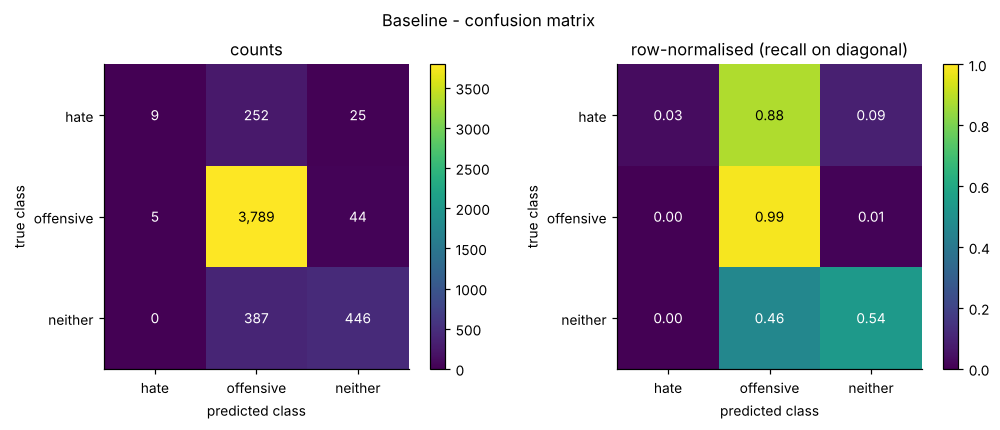

Most frequent confusions (true -> predicted):
   neither    -> offensive  x387    (46.5% of all true 'neither')
   hate       -> offensive  x252    (88.1% of all true 'hate')
   offensive  -> neither    x44     (1.1% of all true 'offensive')
   hate       -> neither    x25     (8.7% of all true 'hate')

Read the two headline numbers together: accuracy 85.6%, hate-class recall 3.1%.
The model finds 9 of the 286 hate-speech messages in the test set (always-'offensive' already scores 77.4% accuracy).
The accuracy looks respectable and comes almost entirely from agreeing with the majority class; for the class the investigation is about, the model is close to blind.


In [11]:
m_base = classification_metrics(y_test, y_pred_base)
print_metrics("BASELINE  bag-of-words + Multinomial NB  [single hold-out split]", m_base)

cm_base = plot_confusion(y_test, y_pred_base,
                         "Baseline - confusion matrix",
                         save="03_baseline_confusion")

print(f"\nRead the two headline numbers together: accuracy {m_base['accuracy']:.1%}, "
      f"hate-class recall {m_base['recall_hate']:.1%}.")
print(f"The model finds {int(round(m_base['recall_hate'] * m_base['support_hate']))} of the "
      f"{m_base['support_hate']} hate-speech messages in the test set "
      f"(always-'offensive' already scores {m_base['majority_rate']:.1%} accuracy).")
if m_base["recall_hate"] < 0.5:
    print("The accuracy looks respectable and comes almost entirely from agreeing with the "
          "majority class; for the class the investigation is about, the model is close to blind.")

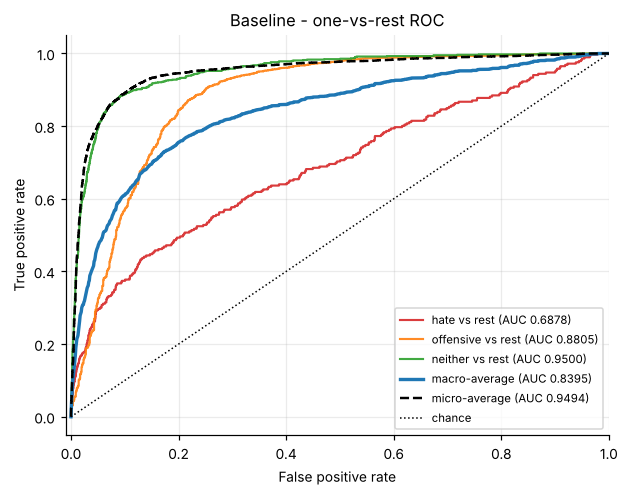

macro AUC 0.8395 | micro AUC 0.9494 | hardest class: hate (0.6878)


In [12]:
roc_base = plot_multiclass_roc(y_test, P_base,
                               "Baseline - one-vs-rest ROC",
                               save="04_baseline_roc")

## Part 6 - Evaluate the baseline (screening)

Same probabilities, different question. Instead of forcing every message into one of three
boxes, take the "hate" column as a score and ask: *if messages above some threshold are sent
to a human examiner, how much hate speech reaches them, and how much else comes along?*

The threshold is where the trade-off actually lives: lower it and less hate speech is missed
but the examiner drowns in false flags; raise it and the queue is short but evidence stays on
the device. The **EER** is a convenient single-number summary, but the honest way to quote a
screening system is the *miss rate at a fixed false-flag rate* (or precision at a fixed
recall) - a threat-assessment unit and a content-moderation queue will pick very different
points on the same curve.

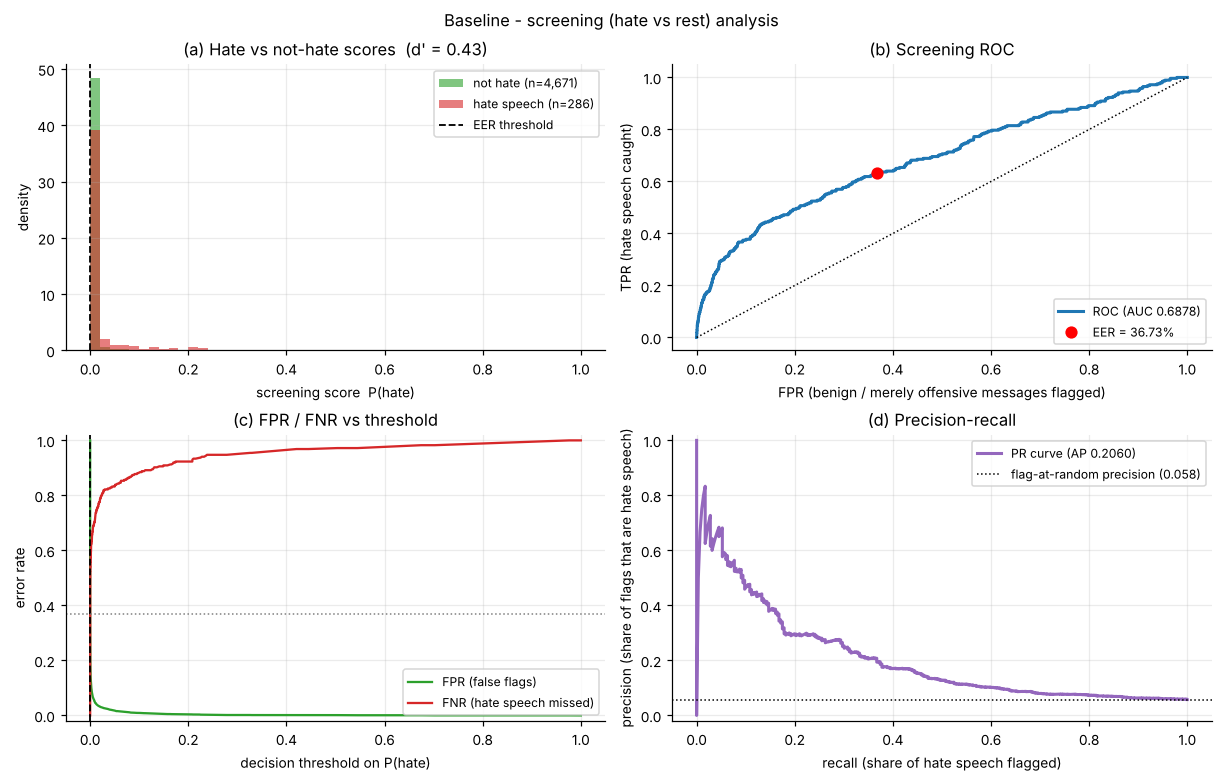

  EER               36.73%   (threshold 0.0000)
  screening AUC    0.6878   average precision 0.2060 (prevalence 0.0577)   d-prime 0.43
  miss rate @ FPR=10.0% :  62.59%   (threshold 0.0027)
  miss rate @ FPR= 5.0% :  70.63%   (threshold 0.0095)
  miss rate @ FPR= 1.0% :  87.41%   (threshold 0.0891)
  precision @ recall=50% :  12.83%
  precision @ recall=80% :   7.38%

Panel (a) is the Naive Bayes signature: 94% of all test messages get P(hate) < 0.01, hate speech included. Multiplying many per-word probabilities drives the output to 0 or 1, so the usable thresholds are all squeezed into a sliver next to zero.


In [13]:
pos_base, neg_base = screening_scores(y_test, P_base)
scr_base = plot_screening(pos_base, neg_base,
                          "Baseline - screening (hate vs rest) analysis",
                          save="05_baseline_screening")

print(f"\nPanel (a) is the Naive Bayes signature: {np.mean(P_base[:, 0] < 0.01):.0%} of all "
      f"test messages get P(hate) < 0.01, hate speech included. Multiplying many per-word "
      f"probabilities drives the output to 0 or 1, so the usable thresholds are all "
      f"squeezed into a sliver next to zero.")

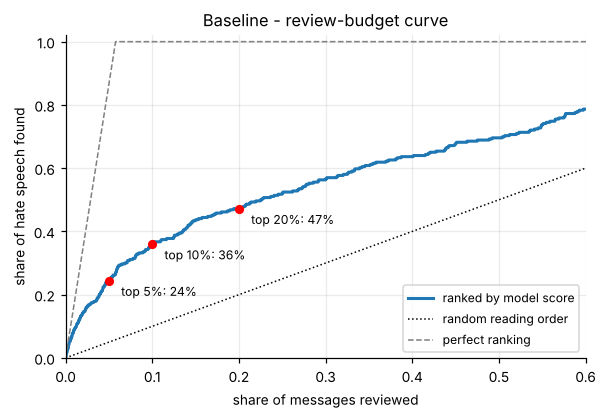

hate speech found after reviewing the top  5%: 24.5%   10%: 36.0%   20%: 47.2%


In [14]:
gain_base, budget_base = plot_review_budget(y_test, P_base,
                                            "Baseline - review-budget curve",
                                            save="06_baseline_review_budget")

RESULTS["Baseline (BoW + NB, hold-out)"] = {**m_base, **roc_base, **scr_base, **budget_base}

## Part 7 - Better dataset preparation: normalisation, group k-fold, in-fold augmentation

Four problems with Part 2 that are worth being precise about:

**1. Tweets are not clean text.** Retweet headers, `@mentions`, URLs, HTML entities
(`&amp;`, `&#128514;`), hashtags and stretched words (`sooooo`) all fragment the vocabulary:
`@user1` and `@user2` become two unrelated features, and the model can even learn that a
*particular account name* predicts a class. `normalize_tweet` maps every mention to `<user>`,
every link to `<url>`, decodes entities, strips retweet headers and squeezes character runs.

**2. The corpus contains near-duplicates.** Retweets and copy-pasted jokes appear several
times with different mentions attached. After normalisation they are the *same text* - and a
random split puts one copy in training and another in test, so the model is partly graded on
messages it has memorised. The fix is to assign every message a **group id** (its normalised
text with mentions, links and punctuation removed) and split by group, so all copies travel
together. This is the text equivalent of a subject-disjoint split in biometrics.

**3. A single split is noisy.** Part 2's test set held fewer than 300 hate-speech messages, so
one extra hit or miss moves hate recall by about a third of a point and a different
`random_state` swings it by several. **Stratified group 5-fold** uses every message as a test
case exactly once, against a model that never saw it (or any copy of it). The resulting
*out-of-fold* (OOF) predictions form one complete evaluation set, and the per-fold spread
gives an honest error bar.

**4. People who write hate speech do not want to be detected.** `h@te`, `ha.te`, `haet` are all
readable to a human and invisible to a word-level model. Augmentation manufactures plausible
obfuscated copies of the training messages (leetspeak, inserted separators, dropped and
swapped letters) so the model sees that kind of variation during training.

> **The leakage trap.** Augmentation must happen *inside* the training fold. If you augment
> first and split afterwards, an obfuscated copy of a test message sits in the training set
> and the model is effectively tested on data it memorised - exactly the near-duplicate
> problem from point 2, now manufactured by you. The loop in Part 8 augments the training
> fold only, carries the group ids through the augmentation so the *inner* tuning splits
> stay clean as well, and never touches the test fold.

In [15]:
_RT_HEADER = re.compile(r'^\s*["\']?\s*(?:!+\s*)?(?:rt\s+@\w+:?\s*)+', flags=re.I)
_URL       = re.compile(r"https?://\S+|www\.\S+")
_MENTION   = re.compile(r"@\w+")

def normalize_tweet(text):
    """Tweet-aware normalisation. Stateless (nothing is learned), so it cannot leak."""
    t = html.unescape(str(text))                  # &amp; -> &   &#128514; -> the emoji itself
    t = _RT_HEADER.sub(" ", t)                    # drop leading 'RT @someone:' headers
    t = re.sub(r"\brt\b", " ", t, flags=re.I)     # ... and stray RT markers
    t = _URL.sub(" <url> ", t)                    # every link -> one token
    t = _MENTION.sub(" <user> ", t)               # every account name -> one token
    t = re.sub(r"#(\w+)", r"\1", t)               # '#word' -> 'word' (keep the content)
    t = t.lower()
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)          # 'sooooo' -> 'soo', '!!!!!!' -> '!!'
    return re.sub(r"\s+", " ", t).strip()

def dedup_key(normalized):
    """Group key: the normalised text with placeholders and punctuation removed."""
    k = re.sub(r"<user>|<url>", " ", normalized)
    return " ".join(re.sub(r"[^a-z0-9 ]", " ", k).split())

X_norm = np.array([normalize_tweet(t) for t in texts_raw], dtype=object)
groups = pd.factorize(pd.Series([dedup_key(t) for t in X_norm]))[0]

# ---- Before / after, on benign messages -----------------------------------------------
demo_rng = np.random.default_rng(SEED)
candidates = [i for i in np.flatnonzero(y == NEITHER)
              if ("@" in texts_raw[i] or "http" in texts_raw[i]) and 50 < len(texts_raw[i]) < 110]
for i in demo_rng.choice(candidates, size=min(3, len(candidates)), replace=False):
    print(f"raw       : {mask_text(texts_raw[i], 100)}")
    print(f"basic     : {mask_text(X_basic[i], 100)}")
    print(f"normalised: {mask_text(X_norm[i], 100)}\n")

# ---- How much did normalisation shrink the vocabulary? ---------------------------------
v_basic = len(CountVectorizer().fit(X_basic).vocabulary_)
v_norm  = len(CountVectorizer().fit(X_norm).vocabulary_)
print(f"vocabulary: {v_basic:,} words after basic cleaning -> {v_norm:,} after normalisation "
      f"({1 - v_norm / v_basic:.0%} smaller)")

# ---- How bad was the near-duplicate problem in the Part 2 split? ------------------------
group_sizes = np.bincount(groups)
n_dup_msgs  = int((group_sizes[groups] > 1).sum())
labels_per_group = pd.Series(y).groupby(groups).nunique()
leaked = np.isin(groups[idx_test], groups[idx_train])
print(f"near-duplicate groups: {int((group_sizes > 1).sum()):,} groups covering "
      f"{n_dup_msgs:,} messages ({n_dup_msgs / N:.1%} of the corpus)")
print(f"groups whose copies carry DIFFERENT labels: {int((labels_per_group > 1).sum())}  "
      f"<- identical text, different 'ground truth'")
print(f"Part 2 test messages with a near-duplicate in the Part 2 training set: "
      f"{int(leaked.sum())} of {len(idx_test):,} ({leaked.mean():.1%})")
if leaked.sum() >= 20:
    print(f"   baseline accuracy on those {int(leaked.sum())}: "
          f"{accuracy_score(y_test[leaked], y_pred_base[leaked]):.3f}   "
          f"on the other {int((~leaked).sum()):,}: "
          f"{accuracy_score(y_test[~leaked], y_pred_base[~leaked]):.3f}")

raw       : RT @user: "A day without laughter is a day wasted." ~Charlie Chaplin
basic     : rt @user: "a day without laughter is a day wasted." ~charlie chaplin
normalised: "a day without laughter is a day wasted." ~charlie chaplin

raw       : &#9733; BEST ASIAN MASSAGE ON THE park slope --TOP RATED SPA &#9733; 718-622-0221 - 24 http://t.c...
basic     : &#9733; best asian massage on the park slope --top rated spa &#9733; 718-622-0221 - 24 http://t.c...
normalised: ★ best asian massage on the park slope --top rated spa ★ 718-622-0221 - 24 <url>

raw       : RT @user: See the jumbotron? That&#8217;s where the jig is
basic     : rt @user: see the jumbotron? that&#8217;s where the jig is
normalised: see the jumbotron? that’s where the jig is



vocabulary: 35,852 words after basic cleaning -> 20,220 after normalisation (44% smaller)
near-duplicate groups: 358 groups covering 1,004 messages (4.1% of the corpus)
groups whose copies carry DIFFERENT labels: 33  <- identical text, different 'ground truth'
Part 2 test messages with a near-duplicate in the Part 2 training set: 165 of 4,957 (3.3%)
   baseline accuracy on those 165: 0.885   on the other 4,792: 0.855


In [16]:
# ---- Obfuscation: used for training-time augmentation here and as the attack in Part 10 ----
_LEET       = {"a": "@4", "e": "3", "i": "1!", "o": "0", "s": "$5", "t": "7"}
_HOMOGLYPH  = {"a": "а", "e": "е", "o": "о", "c": "с", "p": "р",
               "x": "х", "y": "у", "i": "і"}       # Cyrillic look-alikes
_WORD_OR_PROTECTED = re.compile(r"(https?://\S+|www\.\S+|@\w+|<\w+>)|([A-Za-z]{4,})")

def _obfuscate_word(w, rng, family):
    if family == "typo":                        # the family the model is TRAINED on
        kind = rng.integers(4)
        if kind == 0:                                               # leetspeak
            ch  = list(w)
            idx = [i for i, c in enumerate(ch) if c.lower() in _LEET]
            if idx:
                for i in rng.choice(idx, size=max(1, len(idx) // 2), replace=False):
                    ch[i] = rng.choice(list(_LEET[ch[i].lower()]))
                return "".join(ch)
            kind = 1                                                # no leet-able letter
        if kind == 1:                                               # inserted separator
            i = rng.integers(1, len(w))
            return w[:i] + rng.choice(list(".-_*")) + w[i:]
        if kind == 2:                                               # dropped letter
            i = rng.integers(1, len(w) - 1)
            return w[:i] + w[i + 1:]
        i = rng.integers(0, len(w) - 1)                             # swapped neighbours
        return w[:i] + w[i + 1] + w[i] + w[i + 2:]
    if family == "unseen":                      # a family the model is NEVER trained on
        if rng.random() < 0.5:                                      # letter spacing
            return " ".join(w)
        return "".join(_HOMOGLYPH.get(c.lower(), c) for c in w)     # homoglyph swap
    raise ValueError(family)

def obfuscate(text, strength, rng, family="typo"):
    """Perturb a fraction `strength` of the words (4+ letters). Mentions, links and the
    <user>/<url> placeholders are left alone. Readable to a person, different to a tokeniser."""
    def repl(m):
        if m.group(1) or rng.random() >= strength:
            return m.group(0)
        return _obfuscate_word(m.group(2), rng, family)
    return _WORD_OR_PROTECTED.sub(repl, text)

def augment_texts(texts, labels, group_ids, n_aug=1, strength=0.3, rng=None):
    """
    Return the originals plus `n_aug` obfuscated copies of every message. Labels and group ids
    are carried along, so a copy can never be separated from its source by a later group split.
    CALL THIS ON TRAINING DATA ONLY.
    """
    rng = rng or np.random.default_rng(SEED)
    out_t, out_y, out_g = [np.asarray(texts, dtype=object)], [labels], [group_ids]
    for _ in range(n_aug):
        out_t.append(np.array([obfuscate(t, strength, rng, "typo") for t in texts], dtype=object))
        out_y.append(labels); out_g.append(group_ids)
    return np.concatenate(out_t), np.concatenate(out_y), np.concatenate(out_g)

# ---- Visual check: never ship an augmentation you have not looked at ------------------
demo = "honestly those people are the absolute worst and everyone knows it <user>"
demo_rng = np.random.default_rng(SEED)
print(f"original          : {demo}")
for k in range(4):
    print(f"typo   (aug {k + 1})    : {obfuscate(demo, 0.5, demo_rng, 'typo')}")
for k in range(2):
    print(f"unseen (attack {k + 1}) : {obfuscate(demo, 0.5, demo_rng, 'unseen')}")
print("\nThe meaning must survive for a human reader -- otherwise the label is now wrong.")

original          : honestly those people are the absolute worst and everyone knows it <user>
typo   (aug 1)    : honestly thos.e peole are the absolute worst and everynoe k*nows it <user>
typo   (aug 2)    : honestly those pe.ople are the absolue worst and everyone nkows it <user>
typo   (aug 3)    : honestly those poeple are the abso.lute worst and everyone knows it <user>
typo   (aug 4)    : hoenstly htose peple are the absolte wors7 and everyone knosw it <user>
unseen (attack 1) : honestly t h o s e people are the a b s o l u t e wоrst and everyone knows it <user>
unseen (attack 2) : honestly thоsе p e o p l e are the absolute wоrst and everyone knows it <user>

The meaning must survive for a human reader -- otherwise the label is now wrong.


## Part 8 - Better model: word + character TF-IDF -> class-weighted logistic regression

Four changes over the baseline, each fixing a specific weakness:

| Stage | What it adds |
|---|---|
| **Word TF-IDF, 1-2 grams** | TF-IDF down-weights words that appear everywhere, and bigrams keep a little word order: a slur preceded by "you" or "those" is a different signal from the same word in a song lyric. `sublinear_tf` stops one repeated word from dominating a short message. |
| **Character TF-IDF, 3-5 grams** | The answer to obfuscation and creative spelling. `h@te`, `haaate` and `hater` share most of their character n-grams with `hate` while sharing *no* word-level feature. It also covers the out-of-vocabulary words that the baseline simply dropped. |
| **Logistic regression** | Naive Bayes multiplies per-word probabilities as if words were independent, which makes its probabilities extreme and lets the class prior dominate short messages. Logistic regression fits the weights jointly and gives far better-behaved scores to threshold. |
| **`class_weight="balanced"`** | Re-weights the loss so the 6% class counts as much as the 77% class. This is the single biggest change for hate-class recall - and it costs precision, which Part 9 quantifies. |

**Nested cross-validation.** The regularisation strength `C` is selected by an inner 3-fold
grid search that only ever sees the *outer* training fold, scored on **macro-F1** (selecting
on accuracy would simply re-learn "predict the majority class"). Tuning on the data you then
report on is optimistic; nesting removes that. The inner folds are group-aware too, so an
obfuscated copy never validates against its own original.

Every stateful step (both vectorisers and the classifier) is inside the `Pipeline`, so each
fold refits them from scratch on its own training data - no vocabulary or document frequency
can leak from a test fold.

In [17]:
def build_improved_pipeline(C=1.0):
    """Word + character TF-IDF -> balanced logistic regression. Expects NORMALISED text."""
    return Pipeline([
        ("features", FeatureUnion([
            ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2,
                                     sublinear_tf=True,
                                     token_pattern=r"(?u)<?\b\w\w+\b>?")),   # keeps <user>/<url>
            ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3,
                                     sublinear_tf=True, max_features=60_000)),
        ])),
        ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=1000, tol=1e-3)),
    ])


USE_AUG = (N_AUG > 0) and (not FAST_MODE)
outer_cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
fold_splits = list(outer_cv.split(X_norm, y, groups))           # reused in Part 10

oof_pred  = np.empty(N, dtype=int)                              # out-of-fold decisions
oof_score = np.zeros((N, len(CLASSES)), dtype=float)            # out-of-fold probability matrix
fold_rows, fold_params = [], []
rng_aug = np.random.default_rng(SEED)
t_start = time.perf_counter()

for fold, (tr, te) in enumerate(fold_splits, start=1):
    assert not (set(groups[tr]) & set(groups[te])), "a near-duplicate group straddles the split"

    # -- 1. augment the TRAINING fold only ------------------------------------------------
    if USE_AUG:
        X_tr, y_tr, g_tr = augment_texts(X_norm[tr], y[tr], groups[tr], n_aug=N_AUG,
                                         strength=AUG_STRENGTH, rng=rng_aug)
    else:
        X_tr, y_tr, g_tr = X_norm[tr], y[tr], groups[tr]
    X_te, y_te = X_norm[te], y[te]                              # untouched test messages

    # -- 2. inner grid search for C (never sees X_te; group-aware so copies stay together) --
    search = GridSearchCV(build_improved_pipeline(), PARAM_GRID,
                          cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED),
                          scoring="f1_macro", n_jobs=-1, refit=True)
    search.fit(X_tr, y_tr, groups=g_tr)                         # refit=True -> best model, full fold
    model = search.best_estimator_

    # -- 3. score the held-out messages ---------------------------------------------------
    P = model.predict_proba(X_te)
    oof_score[np.ix_(te, np.searchsorted(CLASSES, model.classes_))] = P
    oof_pred[te] = model.classes_[P.argmax(axis=1)]

    row = {"fold": fold, "n_train": len(X_tr), "n_test": len(X_te),
           "accuracy":    accuracy_score(y_te, oof_pred[te]),
           "macro_f1":    f1_score(y_te, oof_pred[te], average="macro"),
           "hate_recall": np.mean(oof_pred[te][y_te == HATE] == HATE),
           "inner_cv_best": search.best_score_}
    fold_rows.append(row); fold_params.append(search.best_params_)
    print(f"fold {fold}/{N_SPLITS}  train={len(X_tr):>6,}  test={len(X_te):>5,}  "
          f"acc={row['accuracy']:.4f}  macro-F1={row['macro_f1']:.4f}  "
          f"hate recall={row['hate_recall']:.4f}  best={search.best_params_}")

print(f"\ntotal cross-validation time: {time.perf_counter() - t_start:.1f} s")
fold_df = pd.DataFrame(fold_rows)
print(fold_df.round(4).to_string(index=False))
for col in ("accuracy", "macro_f1", "hate_recall"):
    print(f"{col:<12} across folds: {fold_df[col].mean():.4f} "
          f"+/- {fold_df[col].std(ddof=1):.4f} (std)")

fold 1/5  train=39,654  test=4,956  acc=0.8880  macro-F1=0.7349  hate recall=0.4476  best={'clf__C': 3.0}


fold 2/5  train=39,654  test=4,956  acc=0.8719  macro-F1=0.7386  hate recall=0.5804  best={'clf__C': 1.0}


fold 3/5  train=39,654  test=4,956  acc=0.8705  macro-F1=0.7391  hate recall=0.6084  best={'clf__C': 1.0}


fold 4/5  train=39,654  test=4,956  acc=0.8612  macro-F1=0.7274  hate recall=0.5909  best={'clf__C': 1.0}


fold 5/5  train=39,648  test=4,959  acc=0.8887  macro-F1=0.7487  hate recall=0.4965  best={'clf__C': 3.0}

total cross-validation time: 212.6 s
 fold  n_train  n_test  accuracy  macro_f1  hate_recall  inner_cv_best
    1    39654    4956    0.8880    0.7349       0.4476         0.7314
    2    39654    4956    0.8719    0.7386       0.5804         0.7290
    3    39654    4956    0.8705    0.7391       0.6084         0.7325
    4    39654    4956    0.8612    0.7274       0.5909         0.7258
    5    39648    4959    0.8887    0.7487       0.4965         0.7257
accuracy     across folds: 0.8760 +/- 0.0120 (std)
macro_f1     across folds: 0.7377 +/- 0.0077 (std)
hate_recall  across folds: 0.5448 +/- 0.0693 (std)


## Part 9 - Evaluate the improved model

The numbers below come from **out-of-fold predictions**: every message in the corpus was
scored by a model trained without it and without any near-duplicate of it. That is a test set
five times the size of Part 2's, and the per-fold standard deviation above is the error bar
that belongs next to each number.

------------------------------------------------------------------------------
  IMPROVED  word+char TF-IDF -> balanced LR  [5-fold group out-of-fold, obfuscation augmentation]
------------------------------------------------------------------------------
  accuracy           0.8760      (majority-class rate 0.7743)
  balanced accuracy  0.7881
  precision (macro)  0.7053      precision (weighted) 0.9002
  recall    (macro)  0.7881      recall    (weighted) 0.8760
  F1        (macro)  0.7375      F1        (weighted) 0.8850
  class       precision    recall        F1   support
  hate           0.3467    0.5448    0.4237     1,430
  offensive      0.9616    0.8888    0.9238    19,190
  neither        0.8078    0.9308    0.8650     4,163
  fold-to-fold std   accuracy 0.0120   macro-F1 0.0077   hate recall 0.0693


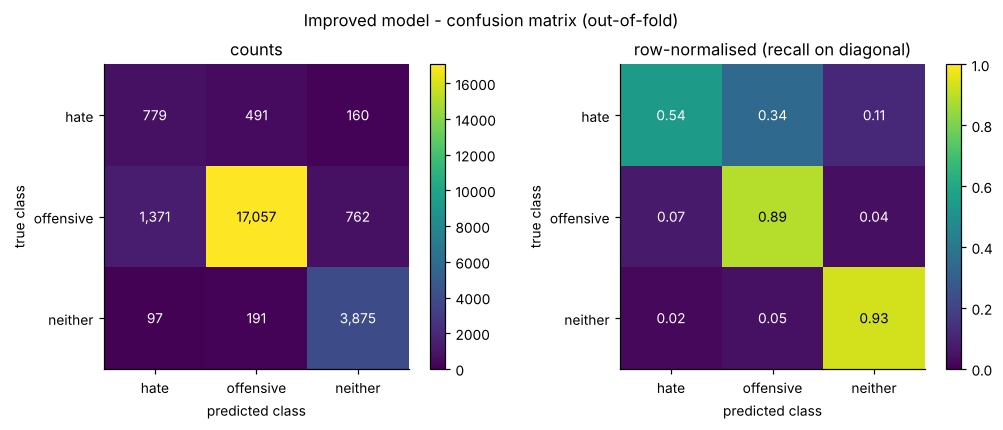

Most frequent confusions (true -> predicted):
   offensive  -> hate       x1,371  (7.1% of all true 'offensive')
   offensive  -> neither    x762    (4.0% of all true 'offensive')
   hate       -> offensive  x491    (34.3% of all true 'hate')
   neither    -> offensive  x191    (4.6% of all true 'neither')

Hate recall went from 3.1% to 54.5%; hate precision is 34.7%.
That precision figure is the price of class weighting: of the messages this model labels 'hate', the rest are mostly the annotators' 'offensive'. Whether that trade is right depends on what happens to a flagged message next -- see Part 13.


In [18]:
m_impr = classification_metrics(y, oof_pred)
print_metrics(f"IMPROVED  word+char TF-IDF -> balanced LR  [{N_SPLITS}-fold group out-of-fold, "
              f"{'obfuscation augmentation' if USE_AUG else 'no augmentation'}]", m_impr)
print(f"  fold-to-fold std   accuracy {fold_df['accuracy'].std(ddof=1):.4f}   "
      f"macro-F1 {fold_df['macro_f1'].std(ddof=1):.4f}   "
      f"hate recall {fold_df['hate_recall'].std(ddof=1):.4f}")

cm_impr = plot_confusion(y, oof_pred,
                         "Improved model - confusion matrix (out-of-fold)",
                         save="07_improved_confusion")

print(f"\nHate recall went from {m_base['recall_hate']:.1%} to {m_impr['recall_hate']:.1%}; "
      f"hate precision is {m_impr['precision_hate']:.1%}.")
print("That precision figure is the price of class weighting: of the messages this model "
      "labels 'hate', the rest are mostly the annotators' 'offensive'. Whether that trade "
      "is right depends on what happens to a flagged message next -- see Part 13.")

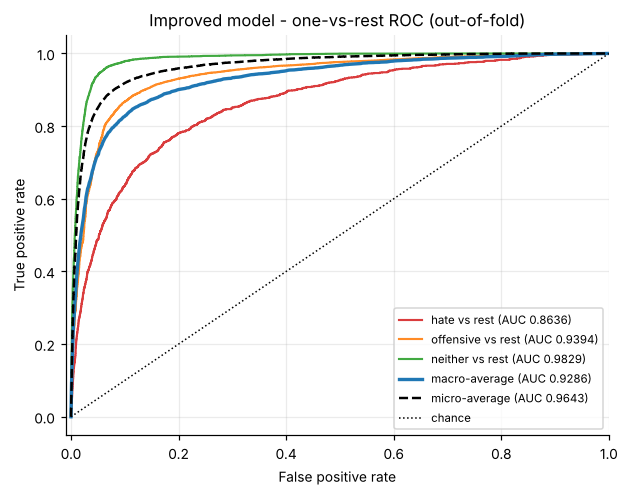

macro AUC 0.9286 | micro AUC 0.9643 | hardest class: hate (0.8636)


In [19]:
roc_impr = plot_multiclass_roc(y, oof_score,
                               "Improved model - one-vs-rest ROC (out-of-fold)",
                               save="08_improved_roc")

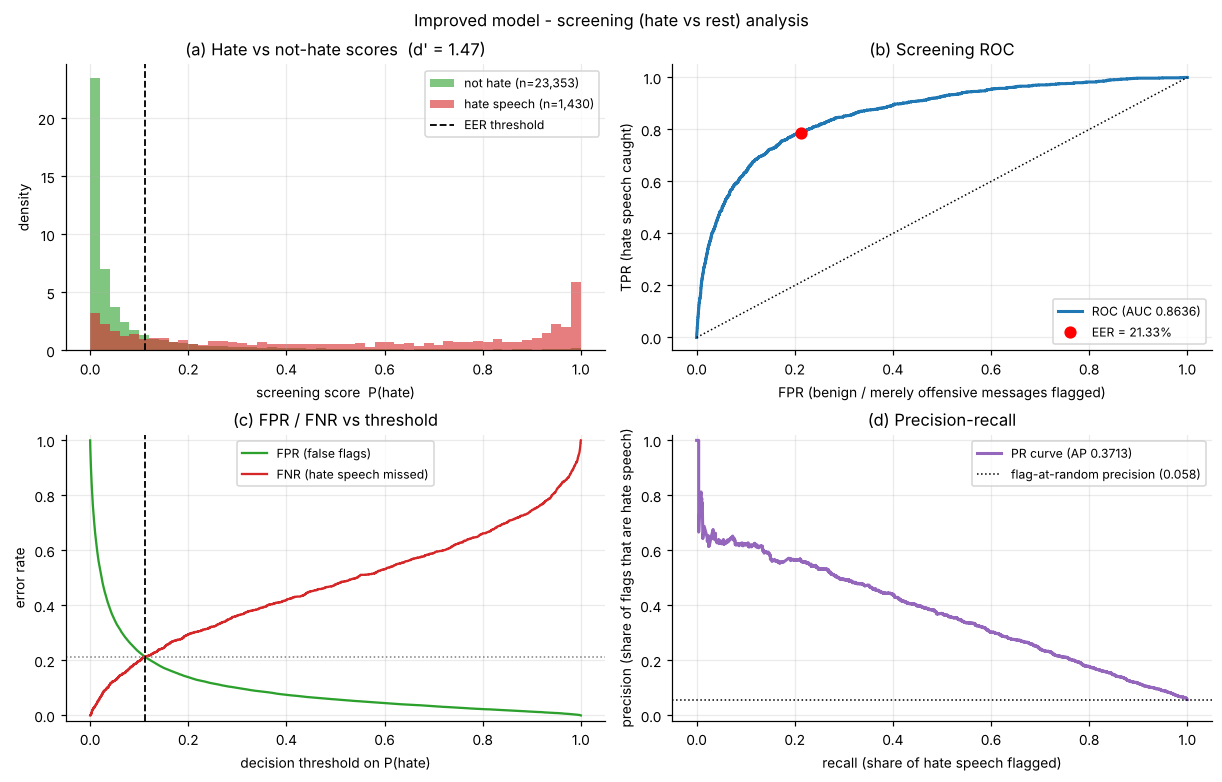

  EER               21.33%   (threshold 0.1115)
  screening AUC    0.8636   average precision 0.3713 (prevalence 0.0577)   d-prime 1.47
  miss rate @ FPR=10.0% :  36.43%   (threshold 0.3027)
  miss rate @ FPR= 5.0% :  51.12%   (threshold 0.5610)
  miss rate @ FPR= 1.0% :  78.81%   (threshold 0.9359)
  precision @ recall=50% :  37.02%
  precision @ recall=80% :  17.73%


In [20]:
pos_impr, neg_impr = screening_scores(y, oof_score)
scr_impr = plot_screening(pos_impr, neg_impr,
                          "Improved model - screening (hate vs rest) analysis",
                          save="09_improved_screening")

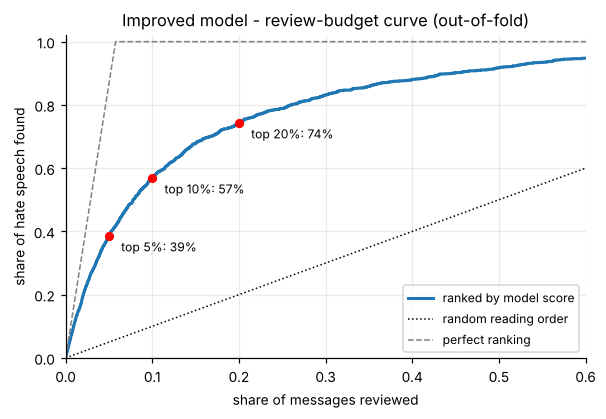

hate speech found after reviewing the top  5%: 38.5%   10%: 56.9%   20%: 74.3%


In [21]:
gain_impr, budget_impr = plot_review_budget(y, oof_score,
                                            "Improved model - review-budget curve (out-of-fold)",
                                            save="10_improved_review_budget")

RESULTS[f"Improved (TF-IDF + LR, {N_SPLITS}-fold)"] = {**m_impr, **roc_impr, **scr_impr,
                                                     **budget_impr}

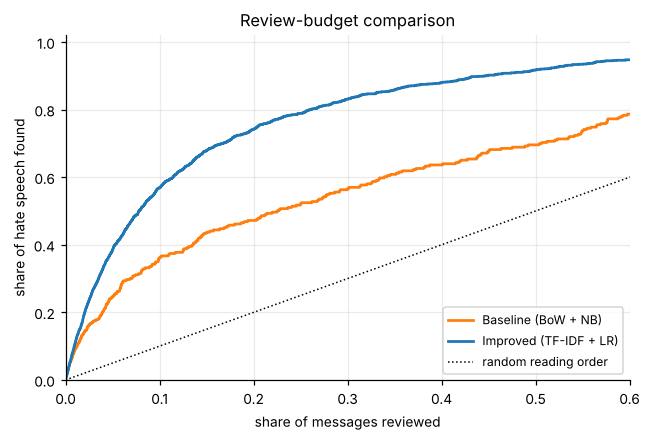

read the top  5% of messages -> baseline finds 24.5% of the hate speech, improved finds 38.5%
read the top 10% of messages -> baseline finds 36.0% of the hate speech, improved finds 56.9%
read the top 20% of messages -> baseline finds 47.2% of the hate speech, improved finds 74.3%


In [22]:
# ---- Side-by-side review-budget curves: the clearest single picture of the improvement ----
fig, ax = plt.subplots(figsize=(5.8, 3.9))
ax.plot(*gain_base, lw=1.8, color="tab:orange", label="Baseline (BoW + NB)")
ax.plot(*gain_impr, lw=1.8, color="tab:blue",   label="Improved (TF-IDF + LR)")
ax.plot([0, 1], [0, 1], "k:", lw=1, label="random reading order")
ax.set_xlabel("share of messages reviewed"); ax.set_ylabel("share of hate speech found")
ax.set_title("Review-budget comparison"); ax.legend(fontsize=8, loc="lower right")
ax.set_xlim(0, 0.6); ax.set_ylim(0, 1.02)
savefig(fig, "11_review_budget_comparison"); plt.show()

for b in (5, 10, 20):
    print(f"read the top {b:>2}% of messages -> baseline finds "
          f"{budget_base[f'found_at_{b}pct']:.1%} of the hate speech, improved finds "
          f"{budget_impr[f'found_at_{b}pct']:.1%}")

## Part 10 - Stress tests: evasion and unintended bias

Everything so far has been **in-distribution**: test messages were drawn from the same pool as
training messages. A deployed detector faces two things that a random split never contains,
and a model can score well in Part 9 while failing both.

**Test A - evasion.** The author of an abusive message edits it so that a human still reads it
the same way but the tokeniser does not. We attack only the abusive test messages (hate or
offensive), at increasing strength, with two perturbation families:

* **typo family** - leetspeak, separators, dropped and swapped letters. This is the family the
  augmented model *was trained on*, so it measures best-case robustness.
* **unseen family** - Cyrillic look-alike letters and letter spacing. No model here ever saw
  these, so this is the honest test of whether robustness generalises.

The figure of merit is the **evasion rate**: the share of abusive messages that the model now
calls "neither". Three models are compared so the effect of each design choice is visible:
the baseline, the improved model *without* augmentation, and the improved model *with* it.

**Test B - unintended bias.** Take benign template sentences ("my ___ neighbors invited us
for dinner") and fill the slot with identity terms and with neutral control adjectives. None
of these messages is abusive, so every flag is a false positive - and if the false-flag rate
depends on *which group is mentioned*, the model has learned that the group's name is itself
evidence of abuse. In a forensic report that is not a rounding error; it is a systematic
error that falls on the people hate speech law exists to protect.

Both tests use the first cross-validation fold: models are trained on its training part and
attacked on its held-out part.

In [23]:
vote   = Counter(tuple(sorted(p.items())) for p in fold_params)
BEST_PARAMS = dict(vote.most_common(1)[0][0])               # most frequently selected setting
BEST_C = BEST_PARAMS["clf__C"]

tr, te = fold_splits[0]
Xa, ya, _ = augment_texts(X_norm[tr], y[tr], groups[tr], n_aug=max(N_AUG, 1),
                          strength=AUG_STRENGTH, rng=np.random.default_rng(SEED))

# Each entry: (fitted model, the preprocessing that model expects on a raw message)
stress_models = {
    "Baseline (BoW + NB)":
        (Pipeline([("bow", CountVectorizer()), ("nb", MultinomialNB())]).fit(X_basic[tr], y[tr]),
         basic_clean),
    "Improved, no augmentation":
        (build_improved_pipeline(C=BEST_C).fit(X_norm[tr], y[tr]), normalize_tweet),
    "Improved + augmentation":
        (build_improved_pipeline(C=BEST_C).fit(Xa, ya), normalize_tweet),
}
STRESS_COLOR = {"Baseline (BoW + NB)": "tab:orange", "Improved, no augmentation": "tab:purple",
                "Improved + augmentation": "tab:blue"}

def predict_raw(name, raw_messages):
    model, prep = stress_models[name]
    return model.predict(np.array([prep(t) for t in raw_messages], dtype=object))

raw_te, y_te = texts_raw[te], y[te]
abusive = (y_te != NEITHER)
print(f"hyperparameters used: {BEST_PARAMS} (selected in {vote.most_common(1)[0][1]}/{N_SPLITS} folds)")
print(f"held-out messages: {len(te):,}  ({abusive.sum():,} abusive, {(~abusive).sum():,} neither)\n")
print(f"{'clean test fold':<28}{'accuracy':>9}{'macro-F1':>10}{'hate rec.':>11}"
      f"{'false flags on neither':>25}")
clean_pred = {}
for name in stress_models:
    p = clean_pred[name] = predict_raw(name, raw_te)
    print(f"{name:<28}{accuracy_score(y_te, p):>9.4f}{f1_score(y_te, p, average='macro'):>10.4f}"
          f"{np.mean(p[y_te == HATE] == HATE):>11.4f}{np.mean(p[~abusive] != NEITHER):>25.4f}")

hyperparameters used: {'clf__C': 1.0} (selected in 3/5 folds)
held-out messages: 4,956  (4,123 abusive, 833 neither)

clean test fold              accuracy  macro-F1  hate rec.   false flags on neither
Baseline (BoW + NB)            0.8628    0.5588     0.0315                   0.4262


Improved, no augmentation      0.8733    0.7322     0.5385                   0.0600


Improved + augmentation        0.8854    0.7420     0.5070                   0.0564


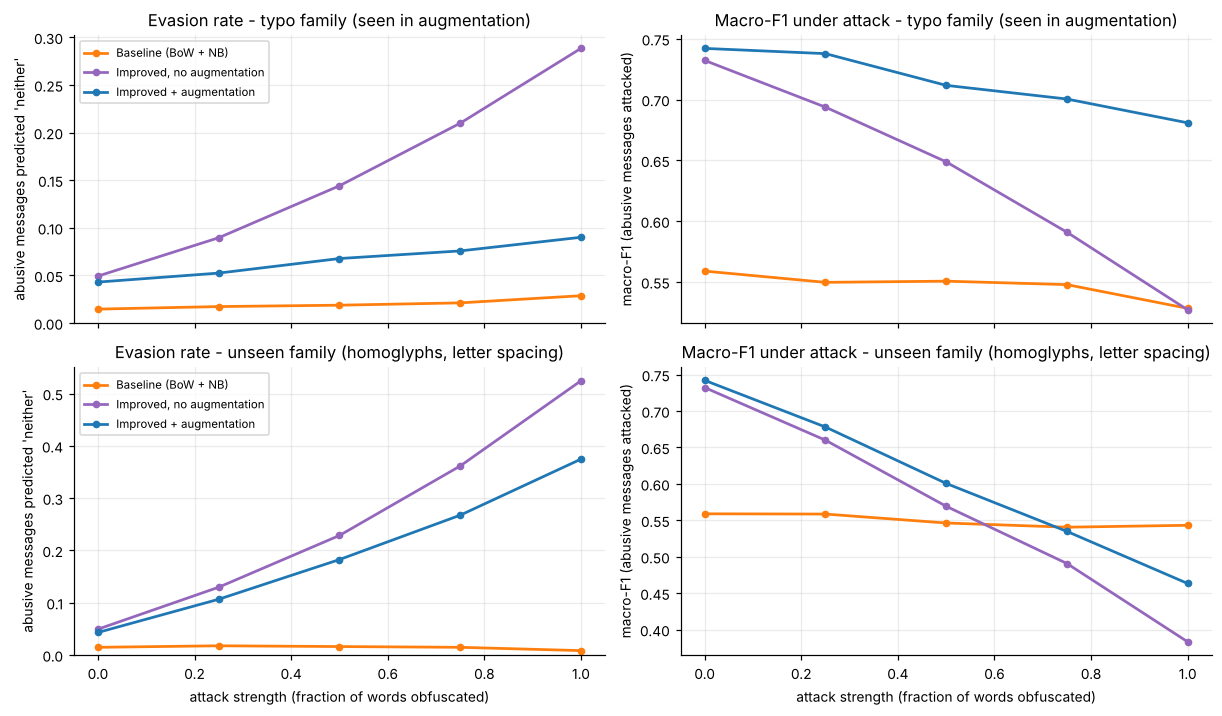


[typo family]  evasion rate at strength  0.00   0.25   0.50   0.75   1.00
  Baseline (BoW + NB)          1.5%   1.7%   1.9%   2.1%   2.9%    macro-F1 0.559 -> 0.528
  Improved, no augmentation    4.9%   8.9%  14.4%  21.0%  28.8%    macro-F1 0.732 -> 0.527
  Improved + augmentation      4.3%   5.2%   6.8%   7.6%   9.0%    macro-F1 0.742 -> 0.681

[unseen family]  evasion rate at strength  0.00   0.25   0.50   0.75   1.00
  Baseline (BoW + NB)          1.5%   1.7%   1.6%   1.5%   0.8%    macro-F1 0.559 -> 0.543
  Improved, no augmentation    4.9%  13.0%  22.8%  36.1%  52.4%    macro-F1 0.732 -> 0.383
  Improved + augmentation      4.3%  10.6%  18.2%  26.7%  37.4%    macro-F1 0.742 -> 0.463

Read the baseline row with its false-flag rate in mind: it flags 43% of the clean 'neither' messages. When its words become unrecognisable it falls back on the class prior, and the prior says 'offensive'. A model that flags nearly everything cannot be evaded -- and cannot be used. Macro-F1 (right-han

In [24]:
# ---- Test A: sweep the attack strength ------------------------------------------------
STRENGTHS = [0.0, 0.25, 0.5, 0.75, 1.0]
evasion = {fam: {name: [] for name in stress_models} for fam in ("typo", "unseen")}
macro_f = {fam: {name: [] for name in stress_models} for fam in ("typo", "unseen")}

for fam in ("typo", "unseen"):
    for s in STRENGTHS:
        atk_rng  = np.random.default_rng(SEED + 1)           # same attack for every model
        attacked = np.array([obfuscate(t, s, atk_rng, fam) if a else t
                             for t, a in zip(raw_te, abusive)], dtype=object)
        for name in stress_models:
            p = predict_raw(name, attacked)
            evasion[fam][name].append(np.mean(p[abusive] == NEITHER))
            macro_f[fam][name].append(f1_score(y_te, p, average="macro"))

fig, ax = plt.subplots(2, 2, figsize=(11, 6.4), sharex=True)
for r, fam in enumerate(("typo", "unseen")):
    for name in stress_models:
        ax[r, 0].plot(STRENGTHS, evasion[fam][name], marker="o", ms=4, lw=1.8,
                      color=STRESS_COLOR[name], label=name)
        ax[r, 1].plot(STRENGTHS, macro_f[fam][name], marker="o", ms=4, lw=1.8,
                      color=STRESS_COLOR[name], label=name)
    tag = "typo family (seen in augmentation)" if fam == "typo" else \
          "unseen family (homoglyphs, letter spacing)"
    ax[r, 0].set_title(f"Evasion rate - {tag}")
    ax[r, 0].set_ylabel("abusive messages predicted 'neither'")
    ax[r, 1].set_title(f"Macro-F1 under attack - {tag}")
    ax[r, 1].set_ylabel("macro-F1 (abusive messages attacked)")
    ax[r, 0].set_ylim(0, None); ax[r, 0].legend(fontsize=7.5)
for a in ax[1]:
    a.set_xlabel("attack strength (fraction of words obfuscated)")
savefig(fig, "12_evasion_stress_test"); plt.show()

for fam in ("typo", "unseen"):
    print(f"\n[{fam} family]  evasion rate at strength " + "  ".join(f"{s:>5.2f}" for s in STRENGTHS))
    for name in stress_models:
        print(f"  {name:<28}" + "  ".join(f"{v:>5.1%}" for v in evasion[fam][name])
              + f"    macro-F1 {macro_f[fam][name][0]:.3f} -> {macro_f[fam][name][-1]:.3f}")

base_ff = np.mean(clean_pred["Baseline (BoW + NB)"][~abusive] != NEITHER)
print(f"\nRead the baseline row with its false-flag rate in mind: it flags "
      f"{base_ff:.0%} of the clean 'neither' messages. When its words become unrecognisable "
      f"it falls back on the class prior, and the prior says 'offensive'. A model that flags "
      f"nearly everything cannot be evaded -- and cannot be used. Macro-F1 (right-hand "
      f"panels) is the column that shows what the attack really costs each model.")

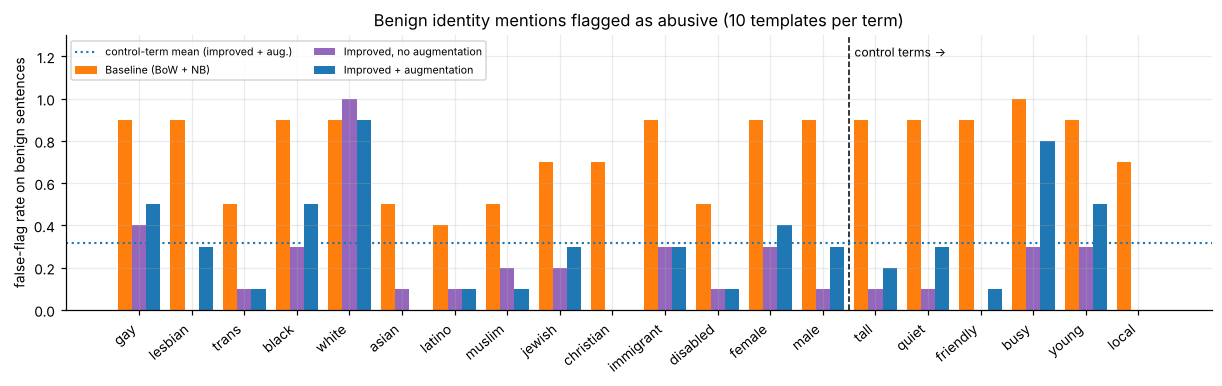

mean false-flag rate on benign template sentences:
          Baseline (BoW + NB)  Improved, no augmentation  Improved + augmentation
kind                                                                             
identity                0.721                      0.229                    0.279
control                 0.883                      0.133                    0.317

[Improved + augmentation]  control-term false-flag rate: 32%
  identity terms flagged clearly MORE often than controls: white (90%), gay (50%), black (50%)
  identity terms flagged clearly LESS often than controls: latino (10%), trans (10%), disabled (10%), muslim (10%), asian (0%), christian (0%)

Two separate things to read off this figure:
  1. Every sentence here is benign, yet even the neutral control sentences are flagged 32% of the time. These are not tweets -- the model is brittle off-domain.
  2. On top of that, the rate depends on WHICH group is named. A term far above the control line has become eviden

In [25]:
# ---- Test B: benign sentences that merely mention an identity --------------------------
TEMPLATES = ["i am a {} person", "my best friend is {}", "proud to be {}",
             "my {} neighbors invited us for dinner", "we need more {} voices in tech",
             "happy birthday to my {} coworker", "{} people deserve respect",
             "i love my {} family", "just met the new {} family next door",
             "our {} students did great work this semester"]
IDENTITY_TERMS = ["gay", "lesbian", "trans", "black", "white", "asian", "latino", "muslim",
                  "jewish", "christian", "immigrant", "disabled", "female", "male"]
CONTROL_TERMS  = ["tall", "quiet", "friendly", "busy", "young", "local"]

probe_rows = []
for term in IDENTITY_TERMS + CONTROL_TERMS:
    msgs = [t.format(term) for t in TEMPLATES]
    row  = {"term": term, "kind": "identity" if term in IDENTITY_TERMS else "control"}
    for name in stress_models:
        row[name] = float(np.mean(predict_raw(name, msgs) != NEITHER))   # every flag is false
    probe_rows.append(row)
probe = pd.DataFrame(probe_rows)

fig, ax = plt.subplots(figsize=(11, 3.4))
xs, w = np.arange(len(probe)), 0.27
for k, name in enumerate(stress_models):
    ax.bar(xs + (k - 1) * w, probe[name], w, color=STRESS_COLOR[name], label=name)
ax.axvline(len(IDENTITY_TERMS) - 0.5, color="k", ls="--", lw=1)
ax.text(len(IDENTITY_TERMS) - 0.4, 1.2, "control terms ->", fontsize=8)
ref_name = "Improved + augmentation"
ctrl_ref = probe.loc[probe.kind == "control", ref_name].mean()
ax.axhline(ctrl_ref, color=STRESS_COLOR[ref_name], ls=":", lw=1.4,
           label="control-term mean (improved + aug.)")
ax.set_xticks(xs); ax.set_xticklabels(probe["term"], rotation=40, ha="right")
ax.set_ylabel("false-flag rate on benign sentences")
ax.set_title(f"Benign identity mentions flagged as abusive ({len(TEMPLATES)} templates per term)")
ax.legend(fontsize=7, ncol=2, loc="upper left")
ax.set_ylim(0, 1.3)
savefig(fig, "13_identity_term_bias"); plt.show()

summary = probe.groupby("kind")[list(stress_models)].mean().loc[["identity", "control"]]
print("mean false-flag rate on benign template sentences:")
print(summary.round(3).to_string())
ident = probe[probe.kind == "identity"].sort_values(ref_name, ascending=False)
above = ident[ident[ref_name] >= ctrl_ref + 0.15]
below = ident[ident[ref_name] <= ctrl_ref - 0.15]
print(f"\n[{ref_name}]  control-term false-flag rate: {ctrl_ref:.0%}")
print("  identity terms flagged clearly MORE often than controls: "
      + (", ".join(f"{t} ({v:.0%})" for t, v in zip(above["term"], above[ref_name])) or "none"))
print("  identity terms flagged clearly LESS often than controls: "
      + (", ".join(f"{t} ({v:.0%})" for t, v in zip(below["term"], below[ref_name])) or "none"))
print(f"\nTwo separate things to read off this figure:")
print(f"  1. Every sentence here is benign, yet even the neutral control sentences are flagged "
      f"{ctrl_ref:.0%} of the time. These are not tweets -- the model is brittle off-domain.")
if len(above):
    print(f"  2. On top of that, the rate depends on WHICH group is named. A term far above the "
          f"control line has become evidence of abuse in its own right.")
else:
    print(f"  2. In this run no identity term stands clearly above the controls, so there is no "
          f"sign of a group-specific effect beyond the general off-domain brittleness.")
print(f"({len(TEMPLATES)} templates per term -> each rate moves in steps of "
      f"{1/len(TEMPLATES):.0%}; this is a probe, not a benchmark)")

## Part 11 - Error analysis

Aggregate metrics tell you *how much* the system fails; these plots tell you *where*, which
is the part you can act on.

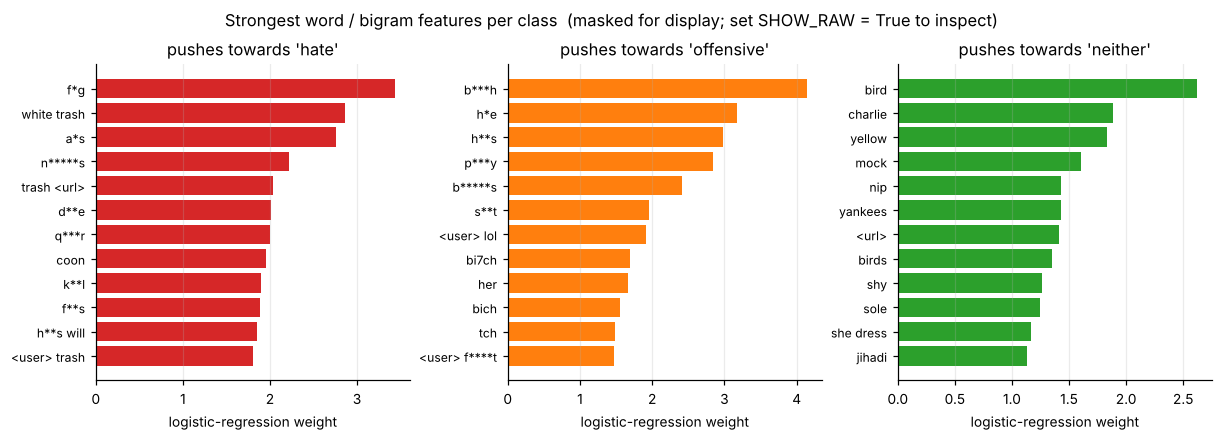

The 'hate' panel is where to look for shortcuts: features that are slurs are the model doing its job, features that are plain identity terms are the mechanism behind Test B.


In [26]:
# ---- What the model actually keys on: strongest word features per class ----------------
explain_model = stress_models["Improved + augmentation"][0]
word_vec   = explain_model.named_steps["features"].transformer_list[0][1]
word_names = np.array(word_vec.get_feature_names_out())
coef       = explain_model.named_steps["clf"].coef_[:, :len(word_names)]   # word block only

fig, axes = plt.subplots(1, 3, figsize=(11, 3.9))
for ax, c, name in zip(axes, CLASSES, CLASS_NAMES):
    row = coef[list(explain_model.named_steps["clf"].classes_).index(c)]
    top = np.argsort(-row)[:12][::-1]
    ax.barh(range(len(top)), row[top], color=CLASS_COLOR[c])
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels([mask_text(w) for w in word_names[top]], fontsize=8)
    ax.set_xlabel("logistic-regression weight"); ax.set_title(f"pushes towards '{name}'")
    ax.grid(axis="y", alpha=0)
fig.suptitle("Strongest word / bigram features per class" +
             ("" if SHOW_RAW else "  (masked for display; set SHOW_RAW = True to inspect)"))
savefig(fig, "14_top_features"); plt.show()

print("The 'hate' panel is where to look for shortcuts: features that are slurs are the model "
      "doing its job, features that are plain identity terms are the mechanism behind Test B.")

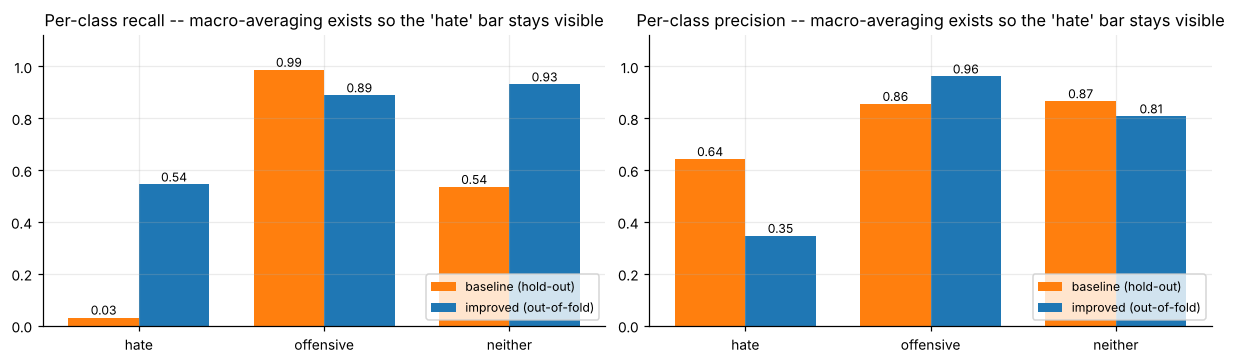

In [27]:
# ---- Which classes are hard? -----------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
xs, w = np.arange(len(CLASSES)), 0.38
for ax, key, ttl in ((axes[0], "recall", "Per-class recall"),
                     (axes[1], "precision", "Per-class precision")):
    b = [m_base[f"{key}_{n}"] for n in CLASS_NAMES]
    i = [m_impr[f"{key}_{n}"] for n in CLASS_NAMES]
    ax.bar(xs - w/2, b, w, label="baseline (hold-out)", color="tab:orange")
    ax.bar(xs + w/2, i, w, label="improved (out-of-fold)", color="tab:blue")
    for x, v in zip(xs - w/2, b): ax.text(x, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    for x, v in zip(xs + w/2, i): ax.text(x, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(xs); ax.set_xticklabels(CLASS_NAMES); ax.set_ylim(0, 1.12)
    ax.set_title(f"{ttl} -- macro-averaging exists so the 'hate' bar stays visible")
    ax.legend(fontsize=8, loc="lower right")
savefig(fig, "15_per_class_recall_precision"); plt.show()

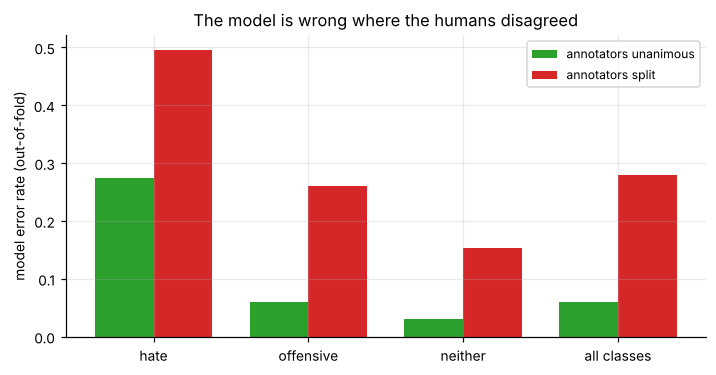

      class  n_unanimous  err_unanimous  n_split  err_split
       hate          263          0.274     1167      0.496
  offensive        14347          0.061     4843      0.260
    neither         2872          0.031     1291      0.154
all classes        17482          0.059     7301      0.279

A 'wrong' prediction on a message the annotators split 2-1 on is not the same kind of error as one on a unanimous message. Part of the remaining error is label noise, and no amount of modelling removes it.


In [28]:
# ---- Do the model's errors follow the annotators' disagreements? ------------------------
wrong = (oof_pred != y)
split_vote = agreement < 1.0
rows = []
for c, name in list(zip(CLASSES, CLASS_NAMES)) + [(None, "all classes")]:
    sel = np.ones(N, dtype=bool) if c is None else (y == c)
    rows.append({"class": name,
                 "n_unanimous":   int((sel & ~split_vote).sum()),
                 "err_unanimous": wrong[sel & ~split_vote].mean() if (sel & ~split_vote).any() else np.nan,
                 "n_split":       int((sel & split_vote).sum()),
                 "err_split":     wrong[sel & split_vote].mean() if (sel & split_vote).any() else np.nan})
agree_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6.4, 3.3))
xs, w = np.arange(len(agree_df)), 0.38
ax.bar(xs - w/2, agree_df["err_unanimous"], w, color="tab:green", label="annotators unanimous")
ax.bar(xs + w/2, agree_df["err_split"],     w, color="tab:red",   label="annotators split")
ax.set_xticks(xs); ax.set_xticklabels(agree_df["class"])
ax.set_ylabel("model error rate (out-of-fold)")
ax.set_title("The model is wrong where the humans disagreed"); ax.legend(fontsize=8)
savefig(fig, "16_error_vs_annotator_agreement"); plt.show()

print(agree_df.round(3).to_string(index=False))
print("\nA 'wrong' prediction on a message the annotators split 2-1 on is not the same kind "
      "of error as one on a unanimous message. Part of the remaining error is label noise, "
      "and no amount of modelling removes it.")

In [29]:
# ---- Look at the actual mistakes ------------------------------------------------------
errors = np.flatnonzero(wrong)
print(f"{len(errors):,} misclassified messages out of {N:,} ({len(errors)/N:.2%} error rate)\n")

conf = oof_score.max(axis=1)
def show_errors(mask, header, k=4):
    idx = np.flatnonzero(mask)
    idx = idx[np.argsort(-conf[idx])][:k]                   # most confident first
    print(f"--- {header} ({int(mask.sum()):,} cases; the {len(idx)} most confident) ---")
    for i in idx:
        v = votes[i]
        print(f"  conf {conf[i]:.2f} | votes h/o/n {v[0]}/{v[1]}/{v[2]} | "
              f"{mask_text(X_norm[i], 88)}")
    print()

show_errors((y == NEITHER) & (oof_pred == HATE),      "true NEITHER predicted HATE  (worst false flag)")
show_errors((y == HATE) & (oof_pred == NEITHER),      "true HATE predicted NEITHER  (worst miss)")
show_errors((y == OFFENSIVE) & (oof_pred == HATE),    "true OFFENSIVE predicted HATE")
show_errors((y == HATE) & (oof_pred == OFFENSIVE),    "true HATE predicted OFFENSIVE")

# High-confidence errors are the dangerous ones: a threshold will not catch them.
print(f"confidence on errors : mean {conf[wrong].mean():.3f}, "
      f"share above 0.90: {(conf[wrong] > 0.9).mean():.1%}")
print(f"confidence on correct: mean {conf[~wrong].mean():.3f}, "
      f"share above 0.90: {(conf[~wrong] > 0.9).mean():.1%}")

3,072 misclassified messages out of 24,783 (12.40% error rate)

--- true NEITHER predicted HATE  (worst false flag) (97 cases; the 4 most confident) ---
  conf 0.93 | votes h/o/n 0/1/2 | “ <user> : dumb b****r” <url>
  conf 0.92 | votes h/o/n 0/0/3 | <user> <user> <user> white people need those weapons to defend themselves from the su...
  conf 0.92 | votes h/o/n 0/1/2 | viola, auntie..you can't call white trash women white trash like this during primetim...
  conf 0.90 | votes h/o/n 0/1/2 | s****d teacher talks to <user> like he's r******d

--- true HATE predicted NEITHER  (worst miss) (160 cases; the 4 most confident) ---
  conf 1.00 | votes h/o/n 2/0/1 | <user> trash eating trash
  conf 0.99 | votes h/o/n 2/0/1 | remember the "yellow badge" nazis used? israel is making muslim women carry a yellow ...
  conf 0.99 | votes h/o/n 2/0/1 | obama’s faves: muslims, black ghetto trash <url> via <user>
  conf 0.99 | votes h/o/n 4/0/2 | ! commence carpet bombing! all iraq soldiers in this vide

## Part 12 - Model comparison, deployment cost, and saving the system

A caveat to read the table with: the baseline row comes from a single random hold-out split
(which contains near-duplicates of its own training data), the improved row from group-aware
out-of-fold predictions over the whole corpus. The improved protocol is the more trustworthy
estimate, and it is also the harder one - the single split got the easier job.

                   Baseline (BoW + NB, hold-out)  Improved (TF-IDF + LR, 5-fold)
accuracy                                  0.8562                          0.8760
f1_macro                                  0.5462                          0.7375
precision_hate                            0.6429                          0.3467
recall_hate                               0.0315                          0.5448
f1_hate                                   0.0600                          0.4237
macro_auc                                 0.8395                          0.9286
average_precision                         0.2060                          0.3713
eer_%                                    36.7253                         21.3311
found_at_10pct                            0.3601                          0.5685


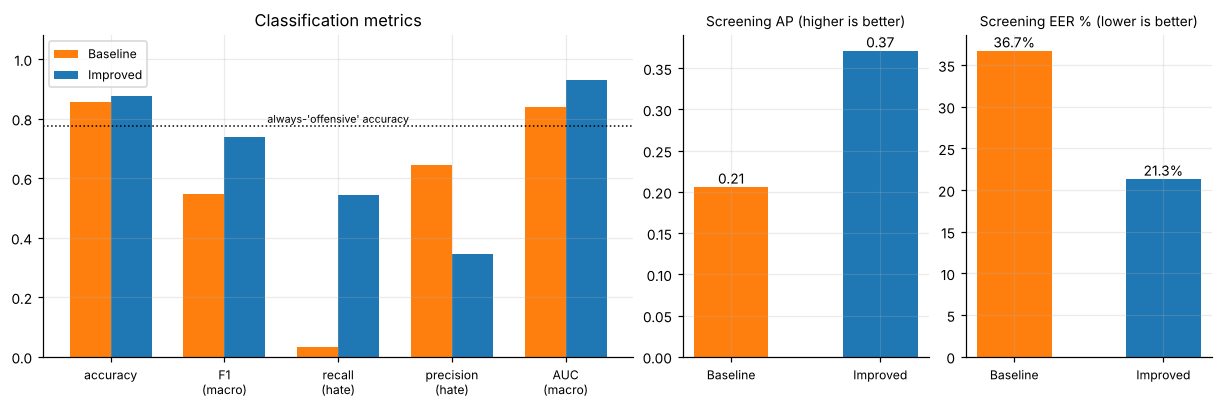

In [30]:
KEYS = ["accuracy", "balanced_accuracy", "precision_macro", "recall_macro", "f1_macro",
        "precision_hate", "recall_hate", "f1_hate", "macro_auc", "screening_auc",
        "average_precision", "eer", "found_at_10pct"]
comparison = pd.DataFrame({name: {k: res.get(k, np.nan) for k in KEYS}
                           for name, res in RESULTS.items()}).T
comparison["eer_%"] = comparison["eer"] * 100
display_cols = ["accuracy", "f1_macro", "precision_hate", "recall_hate", "f1_hate",
                "macro_auc", "average_precision", "eer_%", "found_at_10pct"]
print(comparison[display_cols].round(4).T.to_string())

labels_cmp  = list(RESULTS.keys())
metrics_cmp = ["accuracy", "f1_macro", "recall_hate", "precision_hate", "macro_auc"]
fig, ax = plt.subplots(1, 3, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2.4, 1, 1]})
xs, w = np.arange(len(metrics_cmp)), 0.36
for i, name in enumerate(labels_cmp):
    ax[0].bar(xs + (i - 0.5) * w, [RESULTS[name][m] for m in metrics_cmp], w,
              label=name.split(" (")[0], color=["tab:orange", "tab:blue"][i % 2])
ax[0].axhline(m_base["majority_rate"], color="k", ls=":", lw=1)
ax[0].text(2.0, m_base["majority_rate"] + 0.012, "always-'offensive' accuracy", fontsize=7,
           ha="center")
ax[0].set_xticks(xs)
ax[0].set_xticklabels(["accuracy", "F1\n(macro)", "recall\n(hate)", "precision\n(hate)",
                       "AUC\n(macro)"], fontsize=8)
ax[0].set_ylim(0, 1.08); ax[0].set_title("Classification metrics"); ax[0].legend(fontsize=8)
for j, (key, ttl, scale) in enumerate((("average_precision", "Screening AP (higher is better)", 1),
                                       ("eer", "Screening EER % (lower is better)", 100)), start=1):
    for i, name in enumerate(labels_cmp):
        v = RESULTS[name][key] * scale
        ax[j].bar(i, v, 0.5, color=["tab:orange", "tab:blue"][i % 2])
        ax[j].text(i, v, f"{v:.2f}" if scale == 1 else f"{v:.1f}%", ha="center", va="bottom",
                   fontsize=9)
    ax[j].set_xticks(range(len(labels_cmp)))
    ax[j].set_xticklabels([n.split(" (")[0] for n in labels_cmp], fontsize=8)
    ax[j].set_title(ttl, fontsize=9)
savefig(fig, "17_model_comparison"); plt.show()

In [31]:
# ---- Train the deployment model on all available data ---------------------------------
# Hyperparameters: the setting the inner searches chose most often across the outer folds.
print(f"hyperparameters selected in {vote.most_common(1)[0][1]}/{N_SPLITS} folds: {BEST_PARAMS}")

if USE_AUG:
    X_all, y_all, _ = augment_texts(X_norm, y, groups, n_aug=N_AUG, strength=AUG_STRENGTH,
                                    rng=np.random.default_rng(SEED))
else:
    X_all, y_all = X_norm, y

final_model = build_improved_pipeline(C=BEST_C)
t0 = time.perf_counter(); final_model.fit(X_all, y_all); train_time = time.perf_counter() - t0

def score_messages(raw_messages, model=None):
    """Raw message strings -> (predicted class ids, probability matrix). The one entry point
    a caller needs: it applies the same normalisation the model was trained with."""
    model = model or final_model
    Xn = np.array([normalize_tweet(t) for t in raw_messages], dtype=object)
    P  = model.predict_proba(Xn)
    return model.classes_[P.argmax(axis=1)], P

# ---- Deployment cost: model size and scoring latency ------------------------------------
n_word = len(final_model.named_steps["features"].transformer_list[0][1].vocabulary_)
n_char = len(final_model.named_steps["features"].transformer_list[1][1].vocabulary_)

score_messages(texts_raw[:1])                              # warm-up
t0 = time.perf_counter()
for i in range(200):
    score_messages(texts_raw[i:i + 1])
single_ms = (time.perf_counter() - t0) / 200 * 1000

batch = texts_raw[:5000]
t0 = time.perf_counter(); score_messages(batch); batch_s = time.perf_counter() - t0
throughput = len(batch) / batch_s

print(f"\n--- deployment profile ---")
print(f"training (fit on {len(X_all):,} messages)   : {train_time:.1f} s")
print(f"features                              : {n_word:,} word n-grams + {n_char:,} "
      f"character n-grams = {n_word + n_char:,}")
print(f"single-message latency                : {single_ms:.2f} ms")
print(f"batch throughput                      : {throughput:,.0f} messages/s")
print(f"a phone extraction of 100,000 messages: ~{100_000 / throughput:.0f} s to score")

hyperparameters selected in 3/5 folds: {'clf__C': 1.0}



--- deployment profile ---
training (fit on 49,566 messages)   : 12.9 s
features                              : 125,704 word n-grams + 60,000 character n-grams = 185,704
single-message latency                : 1.66 ms
batch throughput                      : 8,346 messages/s
a phone extraction of 100,000 messages: ~12 s to score


In [32]:
# ---- Persist the model and everything needed to reproduce / audit this run -------------
model_path = MODEL_DIR / "hate_speech_model.joblib"
joblib.dump(final_model, model_path)
MODEL_SHA256 = hashlib.sha256(model_path.read_bytes()).hexdigest()

# Screening thresholds come from the out-of-fold scores: they are the only scores in this
# notebook that were produced by a model that had not seen the message.
THR_FLAG   = scr_impr["thr_at_fpr"][0.01]      # FLAG   : ~1% of non-hate messages exceed this
THR_REVIEW = scr_impr["thr_at_fpr"][0.10]      # REVIEW : ~10% of non-hate messages exceed this

metadata = {
    "created_utc":        datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
    "dataset":            DATA_SOURCE,
    "dataset_sha256":     DATA_SHA256,
    "n_messages":         int(N),
    "class_counts":       {n: int(counts[c]) for c, n in zip(CLASSES, CLASS_NAMES)},
    "label_scheme":       {int(c): n for c, n in zip(CLASSES, CLASS_NAMES)},
    "seed":               SEED,
    "preprocessing":      "normalize_tweet(): unescape HTML, strip RT headers, @mention-><user>, "
                          "link-><url>, strip '#', lowercase, squeeze repeated characters",
    "pipeline":           ["word TF-IDF (1-2 grams)", "char_wb TF-IDF (3-5 grams)",
                           "LogisticRegression(class_weight=balanced)"],
    "hyperparameters":    {k: str(v) for k, v in BEST_PARAMS.items()},
    "augmentation":       f"{N_AUG} obfuscated copy/copies, strength {AUG_STRENGTH}" if USE_AUG else "none",
    "cv":                 f"{N_SPLITS}-fold StratifiedGroupKFold (near-duplicate groups), nested 3-fold tuning",
    "metrics_oof":        {k: float(m_impr[k]) for k in
                           ("accuracy", "f1_macro", "precision_hate", "recall_hate", "f1_hate")},
    "metrics_oof_std":    {c: float(fold_df[c].std(ddof=1)) for c in ("accuracy", "macro_f1", "hate_recall")},
    "macro_auc":          float(roc_impr["macro_auc"]),
    "screening_auc":      float(scr_impr["screening_auc"]),
    "average_precision":  float(scr_impr["average_precision"]),
    "eer":                float(scr_impr["eer"]),
    "thresholds":         {"flag_p_hate": float(THR_FLAG), "review_p_hate": float(THR_REVIEW),
                           "basis": "out-of-fold FPR 1% / 10% on hate-vs-rest"},
    "known_limitations":  ["English tweets from 2017 or earlier", "crowd labels with frequent disagreement on 'hate'",
                           "false flags on benign identity mentions (Part 10B)",
                           "evadable by unseen obfuscation (Part 10A)",
                           "P(hate) is a score, not a calibrated probability"],
    "model_sha256":       MODEL_SHA256,
    "sklearn_version":    sklearn.__version__,
}
meta_path = MODEL_DIR / "model_card.json"
meta_path.write_text(json.dumps(metadata, indent=2))

comparison.to_csv(MODEL_DIR / "results_comparison.csv")
fold_df.to_csv(MODEL_DIR / "cv_folds.csv", index=False)

print(f"model     -> {model_path}  ({model_path.stat().st_size/1e6:.2f} MB)")
print(f"sha256    -> {MODEL_SHA256}")
print(f"model card-> {meta_path}")
print(f"figures   -> {FIG_DIR.resolve()}  ({len(list(FIG_DIR.glob('*.png')))} files)")
print("\n" + json.dumps(metadata, indent=2)[:1100] + "\n...")

# ---- Reload and verify the saved artefact actually works ------------------------------
reloaded = joblib.load(model_path)
assert (reloaded.predict(X_norm[:200]) == final_model.predict(X_norm[:200])).all()
print("\nreload check: OK -- saved model reproduces identical predictions")

model     -> models/hate_speech_model.joblib  (9.91 MB)
sha256    -> 3c8e60757e2f852ff5fde2916e64e1c562aa8dc96bca03ae62263befef83915d
model card-> models/model_card.json
figures   -> /home/claude/work/final3/figures  (17 files)

{
  "created_utc": "2026-10-12 18:38:58",
  "dataset": "davidson-2017",
  "dataset_sha256": "e7a44cb4b68c2c42e5b3e659c8b5f8b9eefe018b569e17ea99223f0ae4bfc6e0",
  "n_messages": 24783,
  "class_counts": {
    "hate": 1430,
    "offensive": 19190,
    "neither": 4163
  },
  "label_scheme": {
    "0": "hate",
    "1": "offensive",
    "2": "neither"
  },
  "seed": 42,
  "preprocessing": "normalize_tweet(): unescape HTML, strip RT headers, @mention-><user>, link-><url>, strip '#', lowercase, squeeze repeated characters",
  "pipeline": [
    "word TF-IDF (1-2 grams)",
    "char_wb TF-IDF (3-5 grams)",
    "LogisticRegression(class_weight=balanced)"
  ],
  "hyperparameters": {
    "clf__C": "1.0"
  },
  "augmentation": "1 obfuscated copy/copies, strength 0.3",
  "cv":


reload check: OK -- saved model reproduces identical predictions


## Part 13 - Forensic triage report

**Scenario.** A phone has been seized under a warrant in a harassment investigation and the
message export contains far more text than anyone can read. The examiner needs a defensible
way to decide *which messages to read first*.

What makes the output forensic rather than just a list of predictions:

1. **Hash before you touch.** The evidence file is hashed (SHA-256) before analysis and every
   message is hashed individually, so any reader of the report can verify that the text in it
   is the text that was on the device.
2. **Record the tool.** The report names the model file by hash, the library version and the
   thresholds, so the analysis can be re-run and must give the same answer.
3. **State the error rate.** The thresholds are tied to measured false-positive rates from
   Part 9, and those rates are printed in the report. A method with a known, stated error
   rate is something a court can weigh; an unexplained "AI flagged it" is not.
4. **Bands, not verdicts.** Messages are sorted into `FLAG` / `REVIEW` / `CLEAR` as a reading
   order. The tool never concludes that a message *is* hate speech - a human does, with
   context the model does not have.

The demonstration messages below are written for this lab (several come from the earlier
keyword-style lab exercise). They are deliberately *not* tweets, which makes this a small
domain-shift test as well.

In [33]:
# ---- 1. The evidence file (in a real case: the export from the extraction tool) --------
seized = pd.DataFrame({
    "msg_id":    [f"MSG-{i:04d}" for i in range(1, 15)],
    "timestamp": pd.date_range("2026-03-02 08:15", periods=14, freq="97min").strftime("%Y-%m-%d %H:%M"),
    "text": [
        "Good morning team, see everyone at 9",
        "I hate those people they are terrible",
        "Thanks for your help with the project yesterday",
        "They are all criminals and thugs",
        "We should ban all of them from our country",
        "Had a great time at the community event",
        "They should go back where they came from",
        "this damn traffic is killing me, what a crappy day",
        "Those people are a disease on this city",
        "Proud of my gay brother for graduating today",
        "th0se pe0ple are verm1n and sh0uld be rem0ved",
        "Really enjoyed the multicultural festival downtown today",
        "All of them should be deported immediately, they are subhuman",
        "Can you send me the lecture notes from Tuesday?",
    ],
})
evidence_path = REPORT_DIR / "seized_messages.csv"
seized.to_csv(evidence_path, index=False)
EVIDENCE_SHA256 = hashlib.sha256(evidence_path.read_bytes()).hexdigest()   # hash BEFORE analysis
print(f"evidence file : {evidence_path}  ({len(seized)} messages)")
print(f"sha256        : {EVIDENCE_SHA256}")

# ---- 2. Score with the saved model (reloaded from disk, exactly as a later re-run would) ----
pred, P = score_messages(seized["text"].tolist(), model=reloaded)
seized["sha256"]     = [hashlib.sha256(t.encode("utf-8")).hexdigest() for t in seized["text"]]
seized["predicted"]  = [CLASS_NAMES[list(CLASSES).index(c)] for c in pred]
seized["p_hate"]     = P[:, list(reloaded.classes_).index(HATE)]
seized["p_offensive"] = P[:, list(reloaded.classes_).index(OFFENSIVE)]
seized["band"] = np.where(seized["p_hate"] >= THR_FLAG, "FLAG",
                 np.where(seized["p_hate"] >= THR_REVIEW, "REVIEW", "CLEAR"))
ranked = seized.sort_values("p_hate", ascending=False).reset_index(drop=True)
print("\n" + ranked[["msg_id", "band", "p_hate", "predicted", "text"]]
      .assign(text=lambda d: d["text"].str.slice(0, 58)).round(3).to_string(index=False))

# ---- How did the triage do? (the answer key is the lab author's, and is NOT evidence) ----
LAB_KEY_HATEFUL = {"MSG-0002", "MSG-0004", "MSG-0005", "MSG-0007", "MSG-0009", "MSG-0011",
                   "MSG-0013"}
is_hateful = ranked["msg_id"].isin(LAB_KEY_HATEFUL)
print("\nagainst the lab answer key:")
for band in ("FLAG", "REVIEW", "CLEAR"):
    in_band = ranked["band"] == band
    print(f"  {band:<6}: {int((in_band & is_hateful).sum())} hateful, "
          f"{int((in_band & ~is_hateful).sum())} not hateful")
missed = ranked.loc[is_hateful & (ranked["band"] == "CLEAR"), "text"].tolist()
for t in missed:
    print(f"  hateful but CLEAR  -> {t!r}")
mislabelled = ranked.loc[~is_hateful & (ranked["predicted"] != "neither"), ["text", "predicted"]]
for t, p in mislabelled.itertuples(index=False):
    print(f"  not hateful, but 3-way label '{p}' -> {t!r}")

evidence file : reports/seized_messages.csv  (14 messages)
sha256        : 2c93f665550d882656ddd9343e4a9426dc6de6437a14cb254996773324262f77

  msg_id   band  p_hate predicted                                                       text
MSG-0002 REVIEW   0.782      hate                      I hate those people they are terrible
MSG-0005 REVIEW   0.752      hate                 We should ban all of them from our country
MSG-0004 REVIEW   0.540      hate                           They are all criminals and thugs
MSG-0013 REVIEW   0.433      hate All of them should be deported immediately, they are subhu
MSG-0007 REVIEW   0.388      hate                   They should go back where they came from
MSG-0009 REVIEW   0.373   neither                    Those people are a disease on this city
MSG-0010  CLEAR   0.104   neither               Proud of my gay brother for graduating today
MSG-0008  CLEAR   0.095 offensive         this damn traffic is killing me, what a crappy day
MSG-0014  CLEAR   0.08

In [34]:
# ---- 3. Write the report ---------------------------------------------------------------
def generate_triage_report(ranked, case_id="DF-2026-001", examiner="CPS 4498 Digital Forensics Lab"):
    L = []
    bar = "=" * 86
    L += [bar, "DIGITAL FORENSICS TRIAGE REPORT -- AUTOMATED HATE SPEECH SCREENING", bar,
          f"Case ID            : {case_id}",
          f"Examiner           : {examiner}",
          f"Report generated   : {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S')} UTC",
          "", "EVIDENCE", "-" * 86,
          f"Source file        : {evidence_path.name}",
          f"SHA-256 (pre-analysis): {EVIDENCE_SHA256}",
          f"Messages analysed  : {len(ranked)}",
          "", "TOOL", "-" * 86,
          f"Model file         : {model_path.name}",
          f"Model SHA-256      : {MODEL_SHA256}",
          f"Method             : word + character TF-IDF, class-weighted logistic regression",
          f"Training data      : {DATA_SOURCE} ({N:,} messages; sha256 {DATA_SHA256[:16]}...)",
          f"Library            : scikit-learn {sklearn.__version__}",
          "", "MEASURED ERROR RATES (cross-validated, out-of-fold, on the training corpus)", "-" * 86,
          f"3-way accuracy {m_impr['accuracy']:.3f} | macro-F1 {m_impr['f1_macro']:.3f} | "
          f"hate-class precision {m_impr['precision_hate']:.3f}, recall {m_impr['recall_hate']:.3f}",
          f"Screening AUC {scr_impr['screening_auc']:.3f} | average precision "
          f"{scr_impr['average_precision']:.3f} | EER {scr_impr['eer']*100:.1f}%",
          f"FLAG   band: P(hate) >= {THR_FLAG:.3f}  -> false-positive rate ~1%,  "
          f"misses {scr_impr['miss_at_fpr'][0.01]*100:.0f}% of hate speech",
          f"REVIEW band: P(hate) >= {THR_REVIEW:.3f}  -> false-positive rate ~10%, "
          f"misses {scr_impr['miss_at_fpr'][0.10]*100:.0f}% of hate speech",
          "These rates were measured on English tweets. The evidence is not tweets; expect",
          "the true error rates on this material to be higher.",
          "", "SUMMARY", "-" * 86]
    for band in ("FLAG", "REVIEW", "CLEAR"):
        L.append(f"{band:<7}: {(ranked['band'] == band).sum():>3} message(s)")
    L += ["", "MESSAGES IN RECOMMENDED READING ORDER", "-" * 86]
    for _, r in ranked.iterrows():
        L += [f"[{r['band']:<6}] {r['msg_id']}   {r['timestamp']}   "
              f"P(hate)={r['p_hate']:.3f}  P(offensive)={r['p_offensive']:.3f}  "
              f"3-way label: {r['predicted']}",
              f"         text  : {r['text']}",
              f"         sha256: {r['sha256']}"]
    L += ["", "LIMITATIONS AND REQUIRED HUMAN REVIEW", "-" * 86,
          "1. This is a triage aid. It orders messages for reading; it does not determine that",
          "   any message is hate speech, a threat, or evidence of bias motivation.",
          "2. Every FLAG and REVIEW message must be read in context by a qualified examiner.",
          "3. CLEAR does not mean benign. The model misses hate speech that uses no abusive",
          "   vocabulary and can be evaded by deliberate misspelling (see validation Part 10).",
          "4. The model produces false flags on benign messages that mention identity groups.",
          "5. P(hate) is a ranking score, not a calibrated probability.",
          bar, "END OF REPORT", bar]
    return "\n".join(L)

report_text = generate_triage_report(ranked)
report_path = REPORT_DIR / "forensic_triage_report.txt"
report_path.write_text(report_text, encoding="utf-8")
ranked.to_csv(REPORT_DIR / "forensic_triage_results.csv", index=False)

print(report_text)
print(f"\nreport  -> {report_path}")
print(f"results -> {REPORT_DIR / 'forensic_triage_results.csv'}")
# The evidence file must be byte-identical after analysis.
assert hashlib.sha256(evidence_path.read_bytes()).hexdigest() == EVIDENCE_SHA256
print("evidence integrity check: OK -- file hash unchanged by the analysis")

DIGITAL FORENSICS TRIAGE REPORT -- AUTOMATED HATE SPEECH SCREENING
Case ID            : DF-2026-001
Examiner           : CPS 4498 Digital Forensics Lab
Report generated   : 2026-10-12 18:38:59 UTC

EVIDENCE
--------------------------------------------------------------------------------------
Source file        : seized_messages.csv
SHA-256 (pre-analysis): 2c93f665550d882656ddd9343e4a9426dc6de6437a14cb254996773324262f77
Messages analysed  : 14

TOOL
--------------------------------------------------------------------------------------
Model file         : hate_speech_model.joblib
Model SHA-256      : 3c8e60757e2f852ff5fde2916e64e1c562aa8dc96bca03ae62263befef83915d
Method             : word + character TF-IDF, class-weighted logistic regression
Training data      : davidson-2017 (24,783 messages; sha256 e7a44cb4b68c2c42...)
Library            : scikit-learn 1.9.1

MEASURED ERROR RATES (cross-validated, out-of-fold, on the training corpus)
------------------------------------------------

## Part 14 - Limitations, legal and ethical notes, and where to take this next

Numbers quoted below are from the reference run of this notebook on the real corpus
(seed 42); yours should match to within rounding.

### Read the numbers with these caveats

1. **The labels are opinions, and often split ones.** Only about 18% of the hate-class tweets
   were labelled unanimously, and 33 near-duplicate groups carry *different* labels on the
   same text. The improved model's error rate is about 6% on messages the annotators agreed
   on and about 28% on messages they split on (Part 11). "Ground truth" here means "the
   majority of three crowd workers, reading one tweet with no conversation around it".
2. **The headline number for the class that matters is modest.** Hate-class precision is
   about 0.35 and recall about 0.54, with a fold-to-fold standard deviation of roughly 0.07
   on recall. Reporting hate recall to two decimals, or claiming a two-point difference
   between two models, is over-reading 1,430 examples.
3. **The corpus was collected by keyword search.** The tweets were sampled because they
   contained a term from a hate-speech lexicon, so even the "neither" class is full of
   lexicon words used innocently - the strongest "neither" features in Part 11 (*bird*,
   *yankees*, *charlie*) are exactly that. The model has learned to separate *senses of
   flagged keywords*. It knows much less about messages that contain none, which is why the
   slur-free hateful messages in Part 13 never reached the FLAG band and why ordinary
   off-domain sentences pick up false flags.
4. **Scores are not probabilities.** `class_weight="balanced"` inflates P(hate) by design.
   The thresholds in Parts 12-13 were set empirically from out-of-fold false-positive rates,
   which is legitimate; reading 0.78 as "78% likely to be hate speech" is not.
5. **Robustness was only partly bought.** Augmentation cut the evasion rate of the typo
   family from about 29% to 9% at full strength, but the family it never saw still gets
   about 37% of abusive messages through. An adversary picks the family you did not train on.
6. **False flags depend on which group is named.** In Part 10B three identity terms (*white*,
   *gay*, *black*) were flagged in half or more of the benign sentences, well above the
   neutral control adjectives, while several other terms fell below the controls - and the
   controls themselves were flagged about a third of the time, because short non-tweet
   sentences are off-domain for this model. This corpus has no demographic or dialect labels, so a proper fairness audit is not possible
   here - but published audits of this same dataset found that models trained on it flag
   tweets written in African-American English as abusive at substantially higher rates
   (Davidson, Bhattacharya & Weber, 2019; Sap et al., 2019). Treat that as a known property
   of this model, not a hypothetical.
7. **English, Twitter, 2017 or earlier.** Slang, slurs and coded language drift quickly. A
   model like this ages, and nothing in it will tell you when it has.

### Legal and ethical notes

* **"Hate speech" is not a legal category in the United States.** Most of it is protected
  speech. What an investigation actually needs is narrower: true threats, harassment,
  incitement, or evidence of bias motivation that supports a hate-crime enhancement. A
  classifier flag establishes none of these. It points an examiner at a message.
* **Admissibility turns on the error rate.** Under *Daubert* and Federal Rule of Evidence 702
  a court asks whether a technique has been tested, whether its error rate is known, and
  whether standards govern its use. Parts 9-11 are that documentation, and the Part 13
  report prints it next to the findings. A tool whose error rate you cannot state does not
  belong in a report.
* **Chain of custody applies to models too.** Hash the evidence before analysis, never modify
  it, and record the exact model file, library version and thresholds so that someone else
  can repeat the analysis and get the same answer.
* **Scope and privacy.** Scoring every message on a device also scores the private
  conversations of people who are not under investigation. The warrant defines what may be
  searched; "the tool can read all of it" does not.
* **Context is missing.** Quotation, counter-speech, reclaimed in-group usage, song lyrics
  and sarcasm all look like the real thing to a bag of n-grams. The model sees one message;
  the meaning usually lives in the thread.
* **Examiner wellbeing.** Reading this material is harmful in volume. Ranking, display
  masking and a short review queue are not only efficiency measures.
* **Dual use.** The evasion test in Part 10 is also a recipe for evasion, and a detector is
  also a tool for suppressing speech. Know which one you are building.

### Natural extensions

| Direction | Change |
|---|---|
| Other data | Swap the loader for HateXplain (adds target groups and human rationales), Founta et al. 2018 (about 100k tweets) or OLID / OffensEval - nothing downstream changes |
| Stronger features | Replace TF-IDF with sentence embeddings or a fine-tuned transformer (HateBERT, a Twitter-RoBERTa hate model) and keep the entire evaluation toolkit |
| Functional testing | Run HateCheck (Rottger et al., 2021): 29 targeted tests covering negation, counter-speech, reclaimed slurs and spelling variation - a systematic version of Part 10 |
| Calibration | Wrap the model in `CalibratedClassifierCV`, draw a reliability diagram, and compare thresholds before and after |
| Cross-dataset shift | Train here, test on a different corpus, and report the drop - the honest measure of generalisation |
| Label noise | Train on unanimous messages only, or on soft labels built from the vote fractions, and compare |
| Explanations | Per-message feature contributions (the linear model gives them exactly), compared against HateXplain's human rationales |
| Cost-based thresholds | Assign costs to a miss and a false flag for a specific unit, and pick the threshold that minimises expected cost |

---

### Lab questions

Answer from your own run of the notebook. Quote the numbers you are relying on.

**Q1 (10 points).** The baseline reaches about 86% accuracy. Using the Part 5 output, explain
why that figure is misleading, and state which two or three numbers you would report instead
and why.

**Q2 (10 points).** Part 7 groups near-duplicate tweets before splitting and augments only
inside the training fold. Explain what would go wrong if you (a) split at random and
(b) augmented the whole corpus before splitting. For each, say whether the reported score
would be too high or too low.

**Q3 (10 points).** Using the Part 9 screening output, choose a P(hate) threshold for (a) a
threat-assessment unit that would rather read too much than miss something, and (b) a list
of messages to be quoted in a court report. For each, state the false-positive rate, the miss
rate, and roughly how many false flags to expect per 10,000 messages.

**Q4 (10 points).** In Part 10A the baseline has the *lowest* evasion rate of the three
models. Explain why this does not make it the most robust model, and say which column or
panel shows that.

**Q5 (10 points).** Pick one identity term with a high false-flag rate in Part 10B. Set
`SHOW_RAW = True` privately, find the features responsible in Part 11, and propose two ways
to reduce the problem. What would each cost?

**Q6 (10 points).** Look at where the obfuscated message (MSG-0011) and the slur-free hateful
messages landed in the Part 13 report. Rewrite the report's limitations section in your own
words for a reader who is a judge, not an engineer.

**Bonus (20 points).** Do one: (a) retrain on unanimously-labelled messages only and compare
hate-class precision and recall; (b) add a third obfuscation family of your own, show that it
evades the current model, then add it to the augmentation and measure what changes - including
on the original two families; (c) calibrate the model and redraw panel (a) of the screening
figure.